<div style="border-left:7px solid #1A59FD; background:#F3F6FF; padding:16px 20px; border-radius:4px; font-family:Segoe UI, Arial, sans-serif;">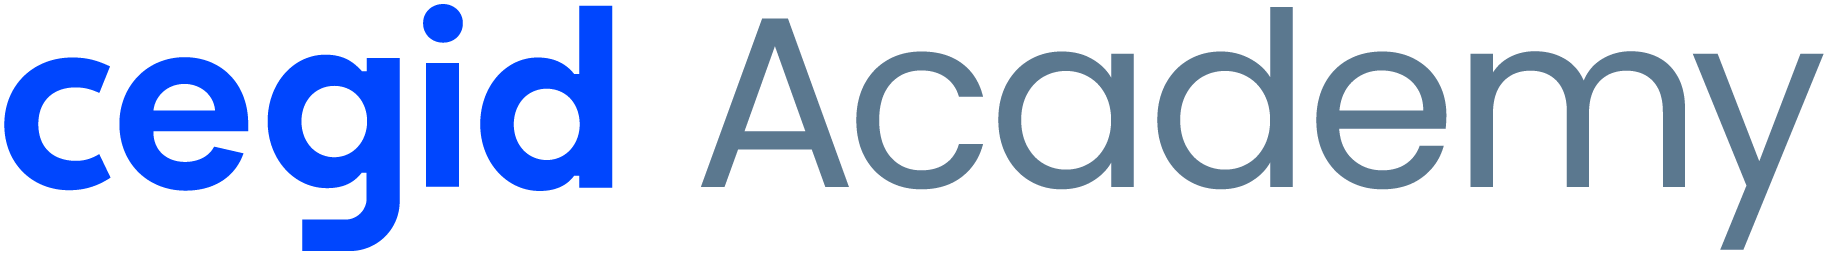<div style="font-size:22px; font-weight:700; color:#1A59FD; line-height:1.2;">Fase 2 &middot; Entendimento dos Dados</div><div style="font-size:14px; color:#0A2540; margin-top:4px;">Implementação de Modelos Analíticos com Python &nbsp;&middot;&nbsp; Projeto CRISP-DM · <i>Data Understanding</i> &nbsp;&middot;&nbsp; Versão <b>formandos</b> &nbsp;&middot;&nbsp; Apoio: <b>M1 · M2.01–M2.05</b></div><div style="margin-top:10px;"><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">1. Entendimento do Negócio</span><span style="display:inline-block;background:#1A59FD;color:#FFFFFF;font-weight:600;border:1px solid #1A59FD;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">2. Entendimento dos Dados</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">3. Preparação dos Dados</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">4. Modelação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">5. Avaliação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">6. Deployment</span></div></div>

#### Identificação do projeto

| Campo | Preenchimento |
|---|---|
| **Projeto** | |
| **Grupo** | |
| **Formandos** | |
| **Data** | |
| **Dataset** | |

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Objetivo</div>Conhecer os dados antes de os transformar. Seguir o <b>workflow estruturado de AED</b> visto no M2.03 (e os gráficos do M1):<ul style="margin:4px 0 2px 0;"><li>Estrutura do dataset</li><li>Qualidade dos dados</li><li>Análise univariada</li><li>Análise bivariada</li><li>Análise multivariada</li></ul>No fim, cada problema encontrado deve dar origem a uma <b>decisão</b> para a Fase 3.</div>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Atenção</div>Nesta fase <b>observa-se, não se transforma</b>. A limpeza, o encoding e o scaling são feitos na Fase 3 (Data Preparation). Visualizar ≠ decorar gráficos — visualizar = <b>interpretar dados</b>.</div>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Data leakage na exploração</div>A AED é feita sobre o dataset completo para <b>compreender</b> os dados — isso está correto. O risco surge quando se <b>tomam decisões de modelação</b> com base em relações com o target calculadas com todas as linhas (incluindo as que vão ser o teste):<ul style="margin:4px 0 2px 0;"><li>escolher variáveis pela correlação ou pelo p-value com o target;</li><li>fixar limites de outliers, categorias raras ou intervalos de discretização a partir destes resultados e reutilizá-los tal e qual;</li><li>ajustar aqui um scaler, um PCA ou uma imputação e aproveitá-los na modelação.</li></ul>Nesta fase <b>regista-se</b> o que se observa; os valores concretos (medianas, limites, categorias, variáveis selecionadas) são <b>recalculados só no treino</b> na Fase 3.</div>

**Índice**

0. Configuração · 1. Recolha e descrição inicial · 2. Estrutura · 3. Qualidade · 4. Análise univariada · 5. Análise bivariada · 6. Análise multivariada · 7. Síntese e decisões

### 0. Configuração
<hr>

Preencher a configuração do projeto. Nas secções seguintes, as células marcadas como **[Classificação]**, **[Regressão]** ou **[Clustering]** só se aplicam a esse tipo de problema — mantenham apenas as que se aplicam ao vosso caso.

**0.1 Bibliotecas**
- Importar `numpy`, `pandas`, `matplotlib.pyplot`, `seaborn` e `scipy.stats`.
- Configurar `pd.set_option("display.max_columns", None)` e `sns.set_theme(style="whitegrid")`.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

**0.2 Configuração do projeto** (usar exatamente os mesmos valores no notebook 03)
- Criar as variáveis: `PROJETO` (nome curto, ex.: `"HR-Intern-Retention"`), `DATA_PATH` (caminho do dataset em `Data/input/`), `TARGET` (variável-alvo; em clustering `None` ou uma variável de referência), `PROBLEM_TYPE` (`"classificacao"`, `"regressao"` ou `"clustering"`), `ID_COLS` (lista de identificadores), `RANDOM_STATE = 42` e `TEST_SIZE = 0.2`.

In [3]:
PROJETO = "HR-Job-Change"
DATA_PATH = "Data/input/Dados_RH_Mudanca_Emprego.csv"
TARGET = "procura_mudanca_emprego"
PROBLEM_TYPE = "classificacao" # binaria (sim/nao) 
ID_COLS = ["id_candidato"]
RANDOM_STATE = 42
TEST_SIZE = 0.2

**0.3 Estrutura de pastas**
- Criar (se não existirem) as pastas `Data/input`, `Data/output`, `Data/analytics` e `Data/models` — sugestão: `pathlib.Path(...).mkdir(parents=True, exist_ok=True)`.
- (Opcional) Criar uma função `guardar_figura(nome)` que grava o gráfico atual em `Data/analytics/`.

In [4]:
PASTAS = ["Data/input", "Data/output", "Data/analytics", "Data/models"]
for pasta in PASTAS:
    Path(pasta).mkdir(parents=True, exist_ok=True)

def guardar_figura(nome):
    caminho = Path("Data/analytics") / f"{nome}.png"
    plt.savefig(caminho, dpi=150, bbox_inches="tight")
    print(f"Figura guardada em: {caminho}")

### 1. Recolha e descrição inicial dos dados
<hr>

- Origem do dataset (fonte, link, data de extração)
- Número de registos e de variáveis
- O que representa cada linha (unidade de análise)?
- Tipo de variáveis (numéricas, categóricas, temporais, texto)
- Unidade de medida de cada variável (€, %, meses, toneladas, …)

***Objetivo:*** perceber "o que tenho em mãos".

**1.1 Carregar o dataset**
- Ler o ficheiro com `pd.read_csv` (ou `pd.read_excel`) para um DataFrame `df`.
- Mostrar o número de registos e de variáveis (`.shape`) e as primeiras linhas (`.head()`).

In [5]:
df = pd.read_csv(DATA_PATH)

display(df.shape)
display(df.head())

(19158, 14)

,id_candidato,cidade,indice_desenvolvimento_cidade,genero,experiencia_relevante,inscricao_universidade,nivel_educacao,area_formacao,anos_experiencia,dimensao_empresa,tipo_empresa,anos_desde_ultimo_emprego,horas_formacao,procura_mudanca_emprego
0,760695,Zona_049,0.910,NaN,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",6 anos,500 a 999,Empresa privada,1 ano,21,Não
1,789493,Zona_006,0.920,Feminino,Com experiência relevante,Não inscrito,Mestrado,Humanidades,Mais de 20 anos,100 a 500,Startup financiada,2 anos,74,Não
2,211612,Zona_007,0.924,NaN,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",9 anos,10 a 49,Empresa privada,1 ano,94,Não
3,521686,Zona_065,0.624,Masculino,Com experiência relevante,Não inscrito,Mestrado,"Ciência, Tecnologia, Engenharia e Matemática",15 anos,10000 ou mais,Empresa privada,1 ano,75,Não
4,146611,Zona_030,0.698,Masculino,Sem experiência relevante,Não inscrito,Mestrado,"Ciência, Tecnologia, Engenharia e Matemática",12 anos,500 a 999,ONG,1 ano,157,Não


##### Análise e Interpretação

> *Quantos registos e variáveis existem? O que representa cada linha (unidade de análise)?*

**Resposta:**

- O dataset contém 19.158 registos e 14 variáveis. A unidade de análise é o candidato: cada linha corresponde a uma pessoa distinta (identificada por id_candidato), descrita pelas suas características demográficas, de formação e de percurso profissional, e pela variável-alvo `procura_mudanca_emprego`

<hr>

**1.2 Resumo das variáveis**
- Construir uma tabela com, para cada coluna: tipo (`dtypes`), nº de valores distintos (`nunique`) e 2–3 exemplos de valores.
- Usar esta tabela para preencher o dicionário de dados abaixo.

In [6]:
print(df.dtypes)

id_candidato                       int64
cidade                               str
indice_desenvolvimento_cidade    float64
genero                               str
experiencia_relevante                str
inscricao_universidade               str
nivel_educacao                       str
area_formacao                        str
anos_experiencia                     str
dimensao_empresa                     str
tipo_empresa                         str
anos_desde_ultimo_emprego            str
horas_formacao                     int64
procura_mudanca_emprego              str
dtype: object


In [7]:
print(df.nunique())

id_candidato                     19158
cidade                             123
indice_desenvolvimento_cidade       93
genero                               3
experiencia_relevante                2
inscricao_universidade               3
nivel_educacao                       5
area_formacao                        6
anos_experiencia                    22
dimensao_empresa                     8
tipo_empresa                         6
anos_desde_ultimo_emprego            6
horas_formacao                     241
procura_mudanca_emprego              2
dtype: int64


In [8]:
df.head(10)

,id_candidato,cidade,indice_desenvolvimento_cidade,genero,experiencia_relevante,inscricao_universidade,nivel_educacao,area_formacao,anos_experiencia,dimensao_empresa,tipo_empresa,anos_desde_ultimo_emprego,horas_formacao,procura_mudanca_emprego
0,760695,Zona_049,0.910,NaN,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",6 anos,500 a 999,Empresa privada,1 ano,21,Não
1,789493,Zona_006,0.920,Feminino,Com experiência relevante,Não inscrito,Mestrado,Humanidades,Mais de 20 anos,100 a 500,Startup financiada,2 anos,74,Não
2,211612,Zona_007,0.924,NaN,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",9 anos,10 a 49,Empresa privada,1 ano,94,Não
3,521686,Zona_065,0.624,Masculino,Com experiência relevante,Não inscrito,Mestrado,"Ciência, Tecnologia, Engenharia e Matemática",15 anos,10000 ou mais,Empresa privada,1 ano,75,Não
4,146611,Zona_030,0.698,Masculino,Sem experiência relevante,Não inscrito,Mestrado,"Ciência, Tecnologia, Engenharia e Matemática",12 anos,500 a 999,ONG,1 ano,157,Não
5,876389,Zona_086,0.896,Masculino,Com experiência relevante,Não inscrito,Ensino Secundário,NaN,13 anos,1000 a 4999,Setor público,2 anos,59,Não
6,849378,Zona_006,0.920,Masculino,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",Mais de 20 anos,50 a 99,Empresa privada,Mais de 4 anos,56,Sim
7,751004,Zona_006,0.920,Masculino,Sem experiência relevante,Curso a tempo inteiro,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",6 anos,NaN,NaN,1 ano,220,Não
8,630471,Zona_023,0.479,NaN,Com experiência relevante,Curso a tempo inteiro,Doutoramento,"Ciência, Tecnologia, Engenharia e Matemática",Mais de 20 anos,10000 ou mais,Empresa privada,Mais de 4 anos,44,Não
9,494403,Zona_056,0.878,Masculino,Sem experiência relevante,Não inscrito,Ensino Básico,NaN,6 anos,Menos de 10,Empresa privada,3 anos,12,Não


In [9]:
resumo = pd.DataFrame({
    "tipo": df.dtypes,
    "n_distintos": df.nunique(),
    "exemplos": [df[col].dropna().unique()[:5].tolist() for col in df.columns]
})

resumo

,tipo,n_distintos,exemplos
id_candidato,int64,19158,"[760695, 789493, 211612, 521686, 146611]"
cidade,str,123,"[Zona_049, Zona_006, Zona_007, Zona_065, Zona_..."
indice_desenvolvimento_cidade,float64,93,"[0.91, 0.92, 0.924, 0.624, 0.698]"
genero,str,3,"[Feminino, Masculino, Outro]"
experiencia_relevante,str,2,"[Com experiência relevante, Sem experiência re..."
inscricao_universidade,str,3,"[Não inscrito, Curso a tempo inteiro, Curso a ..."
nivel_educacao,str,5,"[Licenciatura, Mestrado, Ensino Secundário, Do..."
area_formacao,str,6,"[Ciência, Tecnologia, Engenharia e Matemática,..."
anos_experiencia,str,22,"[6 anos, Mais de 20 anos, 9 anos, 15 anos, 12 ..."
dimensao_empresa,str,8,"[500 a 999, 100 a 500, 10 a 49, 10000 ou mais,..."


##### Análise e Interpretação

> *Que tipos de variáveis existem (numéricas contínuas/discretas, categóricas nominais/ordinais, temporais, identificadores)? Algum tipo parece errado?*

**Resposta:**

- O dataset possui 14 variáveis
- O tipo do `id_candidato` está como número (`int64`) mas é um identificador (a média e soma não terão significado) - converter para texto
- `anos_experiencia`, `anos_desde_ultimo_emprego` e `dimensao_empresa` estão como texto, mas representam quantidades ordenadas - terão de ser convertidas para uma escala numérica ou ordinal na preparação dos dados
- `nivel_educacao` é texto mas tem uma ordem natural
<hr>

**Dicionário de dados** (completar)

| Coluna | Significado | Tipo de variável | Unidade / Exemplos / Notas |
|---|---|---|---|
| `id_candidato` |identificador unico do candidato |Identificador| Nº unico por linha (19 158 valores distintos) - não entra no modelo |
| `cidade` |Código da cidade/zona do candidato? |Categórica nominal |123 valores distintos! Problema na conversão (123 colunas novas...)|
| `indice_desenvolvimento_cidade` |Índice de desenvolvimento da cidade | Numérica contínua|93 valores distintos  |
| `genero` | Género de cada candidato | Categórica nominal| Feminino, Masculino e Outro|
| `experiencia_relevante` |	Se o candidato tem experiência relevante para a área |Categórica nominal (binária) |Com experiência relevante, Sem experiência relevante |
| `inscricao_universidade` | Se está inscrito num curso universitário e em que regime| Categórica nominal|Não inscrito, Curso a tempo inteiro, Curso a tempo parcial|
| `nivel_educacao` | Nível de educação mais alto concluído| Categórica ordinal |Ensino Básico > Ensino Secundário > Licenciatura > Mestrado > Doutoramento |
| `area_formacao` |Área de formação principal |Categórica nominal | 6 categorias únicas|
| `anos_experiencia` |Anos de experiência profissional |Categórica ordinal (guardada como texto) | 22 valores unicos e terá de ser convertido em número|
| `dimensao_empresa` |Número de funcionários da empresa atual |Categórica ordinal (guardada como texto) | 8 intervalos|
| `tipo_empresa` |Tipo da empresa atual |Categórica nominal | 6 categorias |
| `anos_desde_ultimo_emprego` |Tempo (em anos) desde o emprego anterior ou será tempo entre o emprego anterior e o atual? | Categórica ordinal (guardada como texto)| 6 categorias  |
| `horas_formacao` |Número de horas de formação concluídas |Numérica discreta | Em horas e 241 valores diferentes |
| `procura_mudanca_emprego` |Variável-alvo: se o candidato procura mudar de emprego | Categórica nominal (binária)|Sim / Não |


<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Tipos de variáveis (M1 · M2.01):<ul style="margin:4px 0 2px 0;"><li><b>Numérica contínua</b> — qualquer valor num intervalo (salário, idade, fare) → histograma, boxplot;</li><li><b>Numérica discreta</b> — contagens (nº de irmãos, meses) → histograma / bar plot;</li><li><b>Categórica nominal</b> — sem ordem (departamento, curso) → bar plot / countplot;</li><li><b>Categórica ordinal</b> — com ordem natural (nível de escolaridade, classe do bilhete);</li><li><b>Identificador</b> — não tem valor explicativo (ID) → excluir da modelação.</li></ul></div>

### 2. Análise da estrutura dos dados
<hr>

- `df.head()`, `df.info()`, `df.describe()`
- Os tipos de dados estão corretos? (ex.: datas lidas como texto, números como `object`)
- Existem colunas irrelevantes, identificadores ou colunas constantes?
- Existem variáveis que **não estariam disponíveis no momento da previsão** (risco de *data leakage*)?

***Objetivo:*** verificar problemas estruturais.

**2.1 Tipos e não-nulos**
- Aplicar `df.info()`.

In [10]:
df.info() # colunas, tipos, nº de valores não-nulos

<class 'pandas.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_candidato                   19158 non-null  int64  
 1   cidade                         19158 non-null  str    
 2   indice_desenvolvimento_cidade  19158 non-null  float64
 3   genero                         14650 non-null  str    
 4   experiencia_relevante          19158 non-null  str    
 5   inscricao_universidade         18772 non-null  str    
 6   nivel_educacao                 18698 non-null  str    
 7   area_formacao                  16345 non-null  str    
 8   anos_experiencia               19093 non-null  str    
 9   dimensao_empresa               13220 non-null  str    
 10  tipo_empresa                   13018 non-null  str    
 11  anos_desde_ultimo_emprego      18735 non-null  str    
 12  horas_formacao                 19158 non-null  int64  
 1

In [11]:
df.describe().T # estatisticas de todas as colunas

,count,mean,std,min,25%,50%,75%,max
id_candidato,19158.0,547509.220430,259482.271599,100000.000,323343.50,546871.000,770871.50,999982.000
indice_desenvolvimento_cidade,19158.0,0.828848,0.123362,0.448,0.74,0.903,0.92,0.949
horas_formacao,19158.0,65.366896,60.058462,1.000,23.00,47.000,88.00,336.000


In [12]:
df.head()

,id_candidato,cidade,indice_desenvolvimento_cidade,genero,experiencia_relevante,inscricao_universidade,nivel_educacao,area_formacao,anos_experiencia,dimensao_empresa,tipo_empresa,anos_desde_ultimo_emprego,horas_formacao,procura_mudanca_emprego
0,760695,Zona_049,0.910,NaN,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",6 anos,500 a 999,Empresa privada,1 ano,21,Não
1,789493,Zona_006,0.920,Feminino,Com experiência relevante,Não inscrito,Mestrado,Humanidades,Mais de 20 anos,100 a 500,Startup financiada,2 anos,74,Não
2,211612,Zona_007,0.924,NaN,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",9 anos,10 a 49,Empresa privada,1 ano,94,Não
3,521686,Zona_065,0.624,Masculino,Com experiência relevante,Não inscrito,Mestrado,"Ciência, Tecnologia, Engenharia e Matemática",15 anos,10000 ou mais,Empresa privada,1 ano,75,Não
4,146611,Zona_030,0.698,Masculino,Sem experiência relevante,Não inscrito,Mestrado,"Ciência, Tecnologia, Engenharia e Matemática",12 anos,500 a 999,ONG,1 ano,157,Não


##### Análise e Interpretação

> *Os tipos de dados estão corretos? Há colunas com valores em falta?*

**Resposta:**

- `id_candidato` deveria ser texto e não int64
- `anos_experiencia`, `anos_desde_ultimo_emprego` e `dimensao_empresa` estão como texto, mas representam quantidades ordenadas
- `nivel_educacao` é texto mas tem ordem natural - Ensino Básico < Secundário < Licenciatura < Mestrado < Doutoramento
- Redundância a verificar: `cidade` (123 valores) e `indice_desenvolvimento_cidade` (93) estão ligadas - cada cidade tem sempre um único índice, ou seja, o índice é uma característica da cidade.
- valores em falta em 8 colunas - a variável-alvo não tem valores em falta!

<hr>

**2.2 Estatística descritiva geral**
- Aplicar `df.describe(include="all")` (dica: `.T` torna a tabela mais legível).

In [13]:
df.describe(include="all").T # estatisticas de todas as colunas

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_candidato,19158.0,NaN,NaN,NaN,547509.22043,259482.271599,100000.0,323343.5,546871.0,770871.5,999982.0
cidade,19158,123,Zona_006,4355,NaN,NaN,NaN,NaN,NaN,NaN,NaN
indice_desenvolvimento_cidade,19158.0,NaN,NaN,NaN,0.828848,0.123362,0.448,0.74,0.903,0.92,0.949
genero,14650,3,Masculino,13221,NaN,NaN,NaN,NaN,NaN,NaN,NaN
experiencia_relevante,19158,2,Com experiência relevante,13792,NaN,NaN,NaN,NaN,NaN,NaN,NaN
inscricao_universidade,18772,3,Não inscrito,13817,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nivel_educacao,18698,5,Licenciatura,11598,NaN,NaN,NaN,NaN,NaN,NaN,NaN
area_formacao,16345,6,"Ciência, Tecnologia, Engenharia e Matemática",14492,NaN,NaN,NaN,NaN,NaN,NaN,NaN
anos_experiencia,19093,22,Mais de 20 anos,3286,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dimensao_empresa,13220,8,50 a 99,3083,NaN,NaN,NaN,NaN,NaN,NaN,NaN


##### Análise e Interpretação

> *Há valores mínimos/máximos estranhos? Que variáveis têm escalas muito diferentes?*

**Resposta:**

- Não há valores estranhos (nem negativos, zeros)
- `id_candidato` é um identificador pelo que não devemos contabilizar estas estatísticas
- `horas_formacao` vai de 1 a 336 com média de 65 e mediana de 47 - a média acima da mediana indica uma distribuição assimétrica à direita (a maioria dos candidatos tem poucas horas de formação e uma minoria tem muitas)
- `indice_desenvolvimento_cidade`  varia entre 0,448 e 0,949, com média de 0,829 e mediana de 0,903 - a média fica abaixo da mediana: a distribuição é assimétrica à esquerda, com muitos candidatos em cidades muito desenvolvidas

<hr>

**2.3 Listas de variáveis, identificadores e colunas constantes**
- Criar as listas `num_cols` (numéricas) e `cat_cols` (categóricas), **sem** o target nem os `ID_COLS` — `select_dtypes`.
- Identificar colunas com um valor distinto por linha (possíveis identificadores) e colunas constantes.

In [14]:
excluir = ID_COLS + [TARGET] #sem o target nem identificador
X = df.drop(columns=excluir)

#numéricas + categóricas 
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

print("Numéricas:", num_cols)
print("Categóricas:", cat_cols)

# colunas c/valor distinto
n_unicos = df.nunique()

# possíveis identificadores
possiveis_ids = n_unicos[n_unicos == len(df)].index.tolist()

# colunas constantes
constantes = n_unicos[n_unicos <= 1].index.tolist()

print("Possíveis identificadores:", possiveis_ids)
print("Colunas constantes:", constantes)
 

Numéricas: ['indice_desenvolvimento_cidade', 'horas_formacao']
Categóricas: ['cidade', 'genero', 'experiencia_relevante', 'inscricao_universidade', 'nivel_educacao', 'area_formacao', 'anos_experiencia', 'dimensao_empresa', 'tipo_empresa', 'anos_desde_ultimo_emprego']
Possíveis identificadores: ['id_candidato']
Colunas constantes: []


##### Análise e Interpretação

> *Que colunas devem ser excluídas da modelação (identificadores, constantes, redundantes, que revelam o alvo)?*

**Resposta:**

- `id_candidato` deve ser excluído - tem um valor distinto por linha (serve para identificar o candidato e não tem poder preditivo)
- não há colunas constantes pelo que não temos de as excluir
- há uma redondância entre `cidade` e `indice_desenvolvimento_cidade`
<hr>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Sinais de alarme de leakage</div>Desconfiem de uma variável quando:<ul style="margin:4px 0 2px 0;"><li>tem correlação quase perfeita com o target ou separa as classes quase sem erro;</li><li>é registada <b>depois</b> do acontecimento que se quer prever (datas de saída, estado final, avaliações finais, montantes pagos no fim);</li><li>é o target escrito de outra forma (no Titanic, <code>alive</code>) ou uma transformação dele;</li><li>é um identificador ou uma data de registo que reflete a ordem de recolha e, por acaso, se relaciona com o target;</li><li>é um agregado calculado sobre um período que inclui o futuro (ex.: total de compras do ano, quando se prevê em março).</li></ul>Resultados “bons demais” (accuracy ou R² perto de 1) são, na maioria das vezes, sinal de leakage e não de um bom modelo.</div>

### 3. Análise de qualidade dos dados
<hr>

**Valores em falta** — quantos? em que variáveis? que percentagem por coluna? há padrão (MCAR / MAR / MNAR)?

**Valores duplicados** — existem? são legítimos (duas pessoas iguais) ou erros de registo?

**Inconsistências** — valores negativos onde não deveriam existir, percentagens > 100, categorias escritas de formas diferentes (`"HR"`, `"hr "`), unidades misturadas, **códigos de missing disfarçados** (999, −1, `fare = 0`).

**Colunas redundantes** — a mesma informação noutra forma (no Titanic: `class` = `pclass`, `embark_town` = `embarked`, e `alive` = **o próprio alvo disfarçado** → *leakage*).

***Objetivo:*** avaliar a qualidade dos dados.

**3.1 Valores em falta**
- Tabela com nº de nulos e % de nulos por coluna, ordenada — `isnull().sum()`, `isnull().mean()`.

In [15]:
# nº e % de nulos por coluna, ordenado
nulos = pd.DataFrame({
    "n_nulos": df.isnull().sum(),
    "pct_nulos": (df.isnull().mean() * 100).round(2)
}).sort_values("n_nulos", ascending=False)

display(nulos[nulos["n_nulos"] > 0])

# taxa de "Sim" no target quando o valor está em falta vs preenchido (ajuda a ver se é MCAR ou não)
col_nulos = nulos[nulos["n_nulos"] > 0].index

taxa_sim = pd.DataFrame({
    "taxa_sim_em_falta": [((df.loc[df[c].isnull(), TARGET] == "Sim").mean() * 100).round(2) for c in col_nulos],
    "taxa_sim_preenchido": [((df.loc[df[c].notnull(), TARGET] == "Sim").mean() *100).round(2) for c in col_nulos],
}, index=col_nulos).round(3)

taxa_sim


,n_nulos,pct_nulos
tipo_empresa,6140,32.05
dimensao_empresa,5938,30.99
genero,4508,23.53
area_formacao,2813,14.68
nivel_educacao,460,2.40
anos_desde_ultimo_emprego,423,2.21
inscricao_universidade,386,2.01
anos_experiencia,65,0.34


,taxa_sim_em_falta,taxa_sim_preenchido
tipo_empresa,38.83,18.38
dimensao_empresa,40.59,17.90
genero,30.81,23.13
area_formacao,19.52,25.87
nivel_educacao,22.61,24.99
anos_desde_ultimo_emprego,36.41,24.68
inscricao_universidade,31.87,24.79
anos_experiencia,35.38,24.90


##### Análise e Interpretação

> *Quantos valores faltam e em que variáveis? A ausência parece ao acaso (MCAR) ou ligada a outras variáveis (MAR/MNAR)?*

**Resposta:**

- 

<hr>

**3.2 Heatmap de valores nulos**
- `sns.heatmap(df.isnull(), cbar=False)`.

Figura guardada em: Data\analytics\heatmap_nulos.png


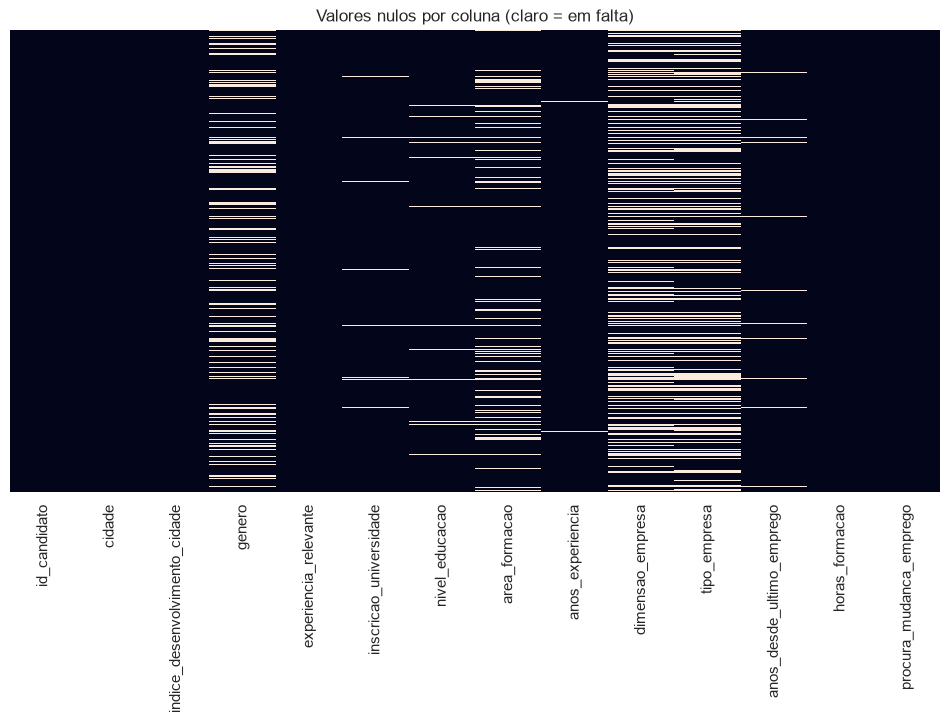

dimensao_empresa em falta,False,True
tipo_empresa em falta,,
False,12440,578
True,780,5360


In [16]:
plt.figure(figsize=(12, 6))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Valores nulos por coluna (claro = em falta)")
guardar_figura("heatmap_nulos")
plt.show()

# os nulos de tipo_empresa e dimensao_empresa aparecem juntos?
nulos_empresa = pd.crosstab(df["tipo_empresa"].isnull(), df["dimensao_empresa"].isnull(),
                            rownames=["tipo_empresa em falta"], colnames=["dimensao_empresa em falta"])

nulos_empresa

##### Análise e Interpretação

> *Os nulos concentram-se em certas colunas ou linhas? Há algum padrão?*

**Resposta:**

- 

<hr>

**3.3 Duplicados**
- Contar linhas duplicadas (`duplicated().sum()`) e IDs repetidos.

In [17]:
print("Linhas duplicadas:", df.duplicated().sum())
print("IDs repetidos:", df["id_candidato"].duplicated().sum())

# sem o ID: há candidatos com exatamente o mesmo perfil?
dup_sem_id = df.drop(columns=ID_COLS).duplicated(keep=False)
print("Linhas duplicadas sem o ID:", df.drop(columns=ID_COLS).duplicated().sum())

df[dup_sem_id].sort_values(df.columns.drop(ID_COLS).tolist()).head(10)

Linhas duplicadas: 0
IDs repetidos: 0
Linhas duplicadas sem o ID: 49


,id_candidato,cidade,indice_desenvolvimento_cidade,genero,experiencia_relevante,inscricao_universidade,nivel_educacao,area_formacao,anos_experiencia,dimensao_empresa,tipo_empresa,anos_desde_ultimo_emprego,horas_formacao,procura_mudanca_emprego
8250,279896,Zona_006,0.92,Feminino,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",6 anos,100 a 500,Empresa privada,1 ano,44,Não
11253,905826,Zona_006,0.92,Feminino,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",6 anos,100 a 500,Empresa privada,1 ano,44,Não
8021,610306,Zona_006,0.92,Masculino,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",15 anos,100 a 500,Empresa privada,2 anos,55,Não
15381,499585,Zona_006,0.92,Masculino,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",15 anos,100 a 500,Empresa privada,2 anos,55,Não
4549,854132,Zona_006,0.92,Masculino,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",15 anos,50 a 99,Empresa privada,1 ano,52,Não
7677,679217,Zona_006,0.92,Masculino,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",15 anos,50 a 99,Empresa privada,1 ano,52,Não
408,772665,Zona_006,0.92,Masculino,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",16 anos,10000 ou mais,Empresa privada,1 ano,48,Não
17562,221084,Zona_006,0.92,Masculino,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",16 anos,10000 ou mais,Empresa privada,1 ano,48,Não
12385,958441,Zona_006,0.92,Masculino,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",9 anos,1000 a 4999,Empresa privada,Mais de 4 anos,22,Não
18071,770936,Zona_006,0.92,Masculino,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",9 anos,1000 a 4999,Empresa privada,Mais de 4 anos,22,Não


##### Análise e Interpretação

> *Existem duplicados? São erros de registo ou casos legítimos?*

**Resposta:**

- 

<hr>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Dados agrupados e dados temporais</div><ul style="margin:4px 0 2px 0;"><li><b>Várias linhas da mesma entidade</b> (o mesmo cliente, doente, estagiário ou máquina): com uma divisão aleatória, a mesma entidade fica no treino e no teste e o modelo é avaliado sobre casos que já “conhece”. A divisão tem de ser feita <b>por entidade</b> (<code>GroupShuffleSplit</code>, <code>GroupKFold</code>).</li><li><b>Dados com ordem temporal</b> (vendas, séries, registos datados): uma divisão aleatória usa o futuro para prever o passado. A divisão deve ser <b>cronológica</b> (treino = período mais antigo, teste = período mais recente) e a validação cruzada feita com <code>TimeSeriesSplit</code>.</li><li><b>Duplicados exatos</b> que fiquem um no treino e outro no teste inflacionam o resultado: tratam-se antes da divisão (Fase 3, secção 2).</li></ul>Registem na síntese (secção 7) se o vosso dataset tem alguma destas estruturas.</div>

**3.4 Intervalos das variáveis numéricas**
- Mostrar mínimo e máximo de cada numérica e assinalar as que têm valores negativos.

In [18]:
intervalos = df[num_cols].agg(["min", "max"]).T
intervalos["tem_negativos"] = intervalos["min"] < 0

intervalos

,min,max,tem_negativos
indice_desenvolvimento_cidade,0.448,0.949,False
horas_formacao,1.000,336.000,False


##### Análise e Interpretação

> *Há valores impossíveis (negativos, % > 100, códigos como 999 ou 0 improvável)?*

**Resposta:**

- 

<hr>

**3.5 Categorias escritas de formas diferentes**
- Para cada categórica, comparar o nº de categorias antes e depois de `str.strip().str.lower()` e listar as categorias.

In [19]:
for col in cat_cols + [TARGET]:
    original = df[col].dropna()
    limpo = original.str.strip().str.lower()
    print(f"{col}: {original.nunique()} categorias -> {limpo.nunique()} depois de strip/lower")
    #if col != "cidade": # cidade tem 123 categorias, não listar
    print("", sorted(original.unique()))

cidade: 123 categorias -> 123 depois de strip/lower
 ['Zona_001', 'Zona_002', 'Zona_003', 'Zona_004', 'Zona_005', 'Zona_006', 'Zona_007', 'Zona_008', 'Zona_009', 'Zona_010', 'Zona_011', 'Zona_012', 'Zona_013', 'Zona_014', 'Zona_015', 'Zona_016', 'Zona_017', 'Zona_018', 'Zona_019', 'Zona_020', 'Zona_021', 'Zona_022', 'Zona_023', 'Zona_024', 'Zona_025', 'Zona_026', 'Zona_027', 'Zona_028', 'Zona_029', 'Zona_030', 'Zona_031', 'Zona_032', 'Zona_033', 'Zona_034', 'Zona_035', 'Zona_036', 'Zona_037', 'Zona_038', 'Zona_039', 'Zona_040', 'Zona_041', 'Zona_042', 'Zona_043', 'Zona_044', 'Zona_045', 'Zona_046', 'Zona_047', 'Zona_048', 'Zona_049', 'Zona_050', 'Zona_051', 'Zona_052', 'Zona_053', 'Zona_054', 'Zona_055', 'Zona_056', 'Zona_057', 'Zona_058', 'Zona_059', 'Zona_060', 'Zona_061', 'Zona_062', 'Zona_063', 'Zona_064', 'Zona_065', 'Zona_066', 'Zona_067', 'Zona_068', 'Zona_069', 'Zona_070', 'Zona_071', 'Zona_072', 'Zona_073', 'Zona_074', 'Zona_075', 'Zona_076', 'Zona_077', 'Zona_078', 'Zona_079'

##### Análise e Interpretação

> *Há categorias duplicadas por diferenças de escrita? Que correções serão necessárias na Fase 3?*

**Resposta:**

- 

<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Tipos de <i>missing data</i> (M3.02):<ul style="margin:4px 0 2px 0;"><li><b>MCAR</b> — em falta completamente ao acaso, sem padrão;</li><li><b>MAR</b> — a ausência depende de outras variáveis observadas;</li><li><b>MNAR</b> — a ausência depende do próprio valor em falta (ex.: salários altos não declarados).</li></ul>O tipo de missing condiciona a estratégia a adotar na Fase 3.</div>

### 4. Análise univariada
<hr>

**Variáveis numéricas** — média, mediana, desvio padrão, mínimo/máximo, assimetria (*skewness*), histogramas, boxplots, outliers (IQR e Z-score), distribuição unimodal ou multimodal.

**Variáveis categóricas** — frequência das categorias, categorias raras.

**Variável-alvo** — balanceamento das classes (classificação) ou distribuição (regressão). **Muito importante!**

***Objetivo:*** ganhar intuição sobre os dados.

**4.1 "Ficha de identidade" das numéricas (M2.03)**
- Tabela com média, mediana, moda, desvio padrão, IQR, amplitude, coeficiente de variação (%), `skew` e `kurtosis`.

In [20]:
# "ficha de identidade" de cada variável numérica
num = df[num_cols]

ficha = pd.DataFrame({
    "media": num.mean(),
    "mediana": num.median(),
    "moda": num.mode().iloc[0],
    "desvio_padrao": num.std(),
    "IQR": num.quantile(0.75) - num.quantile(0.25),
    "amplitude": num.max() - num.min(),
    "CV_%": num.std() / num.mean() * 100,
    "skew": num.skew(),
    "kurtosis": num.kurt()
}).round(3)

ficha

,media,mediana,moda,desvio_padrao,IQR,amplitude,CV_%,skew,kurtosis
indice_desenvolvimento_cidade,0.829,0.903,0.92,0.123,0.18,0.501,14.884,-0.995,-0.539
horas_formacao,65.367,47.000,28.00,60.058,65.00,335.000,91.879,1.819,3.841


##### Análise e Interpretação

> *Onde está o valor típico de cada variável? Há diferenças grandes entre média e mediana? Que variáveis são assimétricas (|skew| > 1) ou muito dispersas?*

**Resposta:**

- 

<hr>

**4.2 Histogramas com KDE**
- Um histograma (`sns.histplot(..., kde=True)`) por variável numérica, com a média e a mediana assinaladas.

Figura guardada em: Data\analytics\histogramas_numericas.png


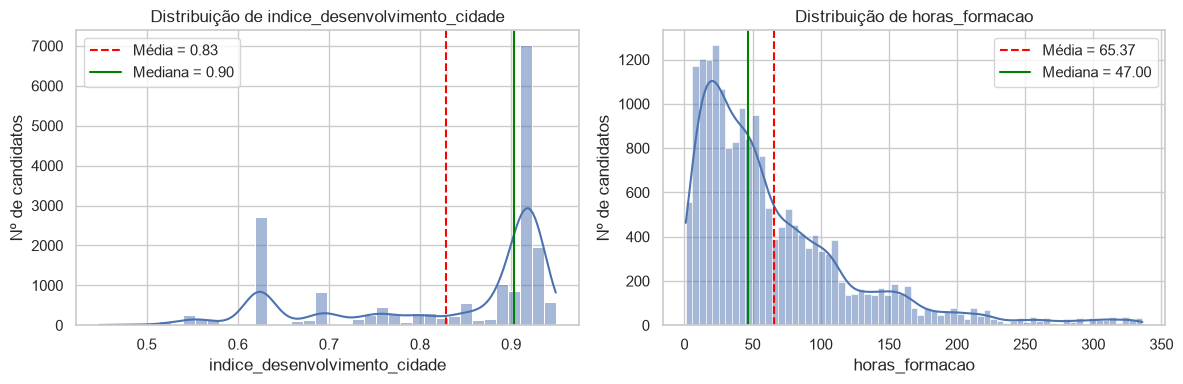

In [21]:
fig, axes = plt.subplots(1, len(num_cols), figsize=(12, 4))

for ax, col in zip(np.atleast_1d(axes), num_cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.axvline(df[col].mean(), color="red", linestyle="--", label=f"Média = {df[col].mean():.2f}")
    ax.axvline(df[col].median(), color="green", linestyle="-", label=f"Mediana = {df[col].median():.2f}")
    ax.set_title(f"Distribuição de {col}")
    ax.set_ylabel("Nº de candidatos")
    ax.legend()

plt.tight_layout()
guardar_figura("histogramas_numericas")
plt.show()

##### Análise e Interpretação

> *As distribuições são unimodais ou multimodais? Simétricas ou assimétricas?*

**Resposta:**

- 

<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Leitura (M2.03/M2.04): média ≫ mediana → assimetria à direita; |skew| > 1 → muito assimétrica; curtose alta → caudas pesadas (mais outliers); CV alto → grande dispersão relativa.</div>

**4.3 Boxplots**
- Um boxplot por variável numérica.

Figura guardada em: Data\analytics\boxplots_numericas.png


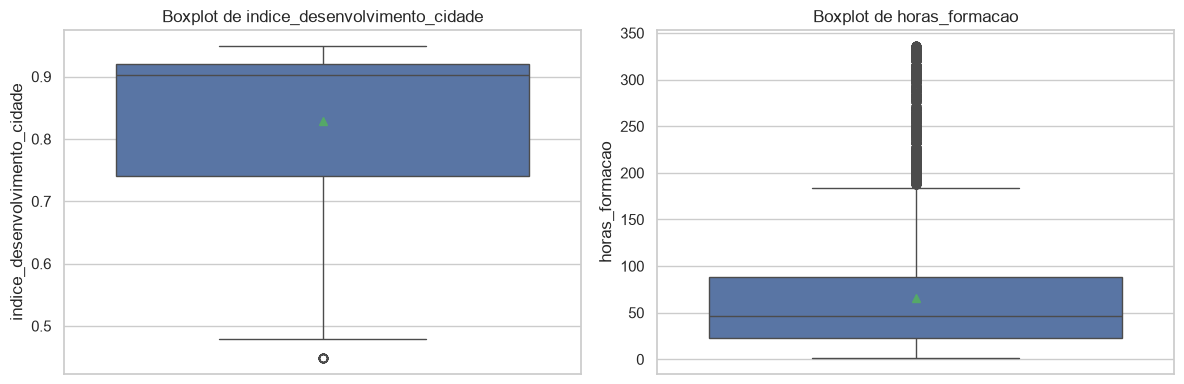

In [22]:
fig, axes = plt.subplots(1, len(num_cols), figsize=(12, 4))

for ax, col in zip(np.atleast_1d(axes), num_cols):
    sns.boxplot(y=df[col], ax=ax, showmeans=True)
    ax.set_title(f"Boxplot de {col}")

plt.tight_layout()
guardar_figura("boxplots_numericas")
plt.show()

##### Análise e Interpretação

> *Que variáveis apresentam pontos para lá dos bigodes? Parecem erros ou valores reais?*

**Resposta:**

- 

<hr>

**4.4 Normalidade (M2.04)**
- QQ-plot de cada numérica (`stats.probplot(..., dist="norm", plot=ax)`).
- Teste de Shapiro-Wilk (`stats.shapiro`) numa tabela com W, p-value e conclusão.

Figura guardada em: Data\analytics\qqplots_numericas.png


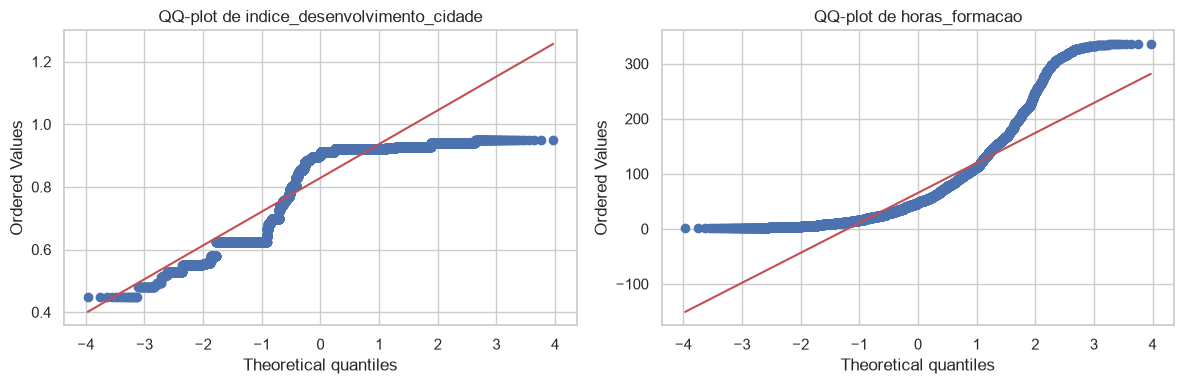

,W,p_value,conclusao
variavel,,,
indice_desenvolvimento_cidade,0.7721,4.427794e-64,rejeita a normalidade
horas_formacao,0.8271,7.143949e-59,rejeita a normalidade


In [23]:
# QQ-plots
fig, axes = plt.subplots(1, len(num_cols), figsize=(12, 4))

for ax, col in zip(np.atleast_1d(axes), num_cols):
    stats.probplot(df[col], dist="norm", plot=ax)
    ax.set_title(f"QQ-plot de {col}")

plt.tight_layout()
guardar_figura("qqplots_numericas")
plt.show()

# Shapiro-Wilk: o p-value só é exato até 5000 observações, por isso usamos uma amostra de 5000
resultados = []
for col in num_cols:
    amostra = df[col].sample(5000, random_state=RANDOM_STATE)
    W, p = stats.shapiro(amostra)
    resultados.append({
        "variavel": col,
        "W": round(W, 4),
        "p_value": p,
        "conclusao": "segue a normal" if p >= 0.05 else "rejeita a normalidade"
    })

shapiro = pd.DataFrame(resultados).set_index("variavel")

shapiro

##### Análise e Interpretação

> *Que variáveis se aproximam da normal? Os QQ-plots e os p-values concordam? Em qual confiam e porquê?*

**Resposta:**

- 

<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>H0 do Shapiro-Wilk: os dados seguem uma distribuição normal. Se p &lt; 0,05 rejeita-se a normalidade → preferir mediana/IQR, testes não paramétricos (Mann-Whitney, Kruskal-Wallis, Spearman) ou uma transformação (log). Com amostras grandes o teste rejeita com facilidade: ler sempre em conjunto com o QQ-plot. Para n &gt; 5000 o <code>scipy</code> avisa que o p-value pode não ser exato.</div>

**4.5 Deteção de outliers (M2.04)**
- Criar uma função `conta_outliers(s)` que devolva os limites IQR e o nº de outliers por IQR (1,5×), Z-score (|z| > 3) e percentis (fora de P1–P99).
- Aplicar a todas as numéricas e apresentar numa tabela.

In [24]:
def conta_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (s - s.mean()) / s.std()
    p1, p99 = s.quantile([0.01, 0.99])
    return pd.Series({
        "lim_inf_IQR": lim_inf,
        "lim_sup_IQR": lim_sup,
        "n_outliers_IQR": ((s < lim_inf) | (s > lim_sup)).sum(),
        "n_outliers_Z": (z.abs() > 3).sum(),
        "n_outliers_P1_P99": ((s < p1) | (s > p99)).sum()
    })

outliers = df[num_cols].apply(conta_outliers).T
cols_contagem = ["n_outliers_IQR", "n_outliers_Z", "n_outliers_P1_P99"]
outliers[cols_contagem] = outliers[cols_contagem].astype(int)

outliers

,lim_inf_IQR,lim_sup_IQR,n_outliers_IQR,n_outliers_Z,n_outliers_P1_P99
indice_desenvolvimento_cidade,0.47,1.19,17,17,257
horas_formacao,-74.50,185.50,984,450,294


##### Análise e Interpretação

> *Os métodos concordam? Porquê? Quem são os outliers — erros ou informação rara mas real?*

**Resposta:**

- 

<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div><ul style="margin:4px 0 2px 0;"><li><b>Z-score</b> funciona melhor em distribuições aproximadamente normais;</li><li><b>IQR</b> é mais robusto em distribuições assimétricas;</li><li>Nem todos os outliers são erros: podem representar informação rara mas importante — <b>ver quem são</b> (ex.: no Titanic, os outliers de <code>fare</code> são sobretudo passageiros de 1.ª classe).</li></ul></div>

**4.6 (Opcional) Transformação logarítmica**
- Para as variáveis com |skew| > 1 e sem negativos, comparar o histograma original com o de `np.log1p(...)` e o respetivo skew.

Variáveis a transformar: ['horas_formacao']
Figura guardada em: Data\analytics\transformacao_log.png


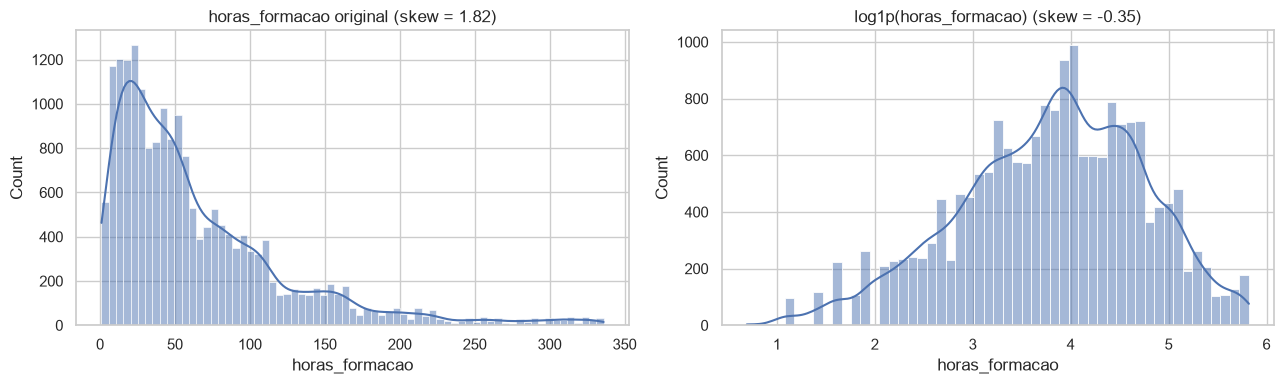

In [25]:
# variáveis muito assimétricas (|skew| > 1) e sem negativos
cols_assimetricas = [c for c in num_cols if abs(df[c].skew()) > 1 and df[c].min() >= 0]
print("Variáveis a transformar:", cols_assimetricas)

fig, axes = plt.subplots(len(cols_assimetricas), 2, figsize=(13, 4 * len(cols_assimetricas)), squeeze=False)

for i, col in enumerate(cols_assimetricas):
    col_log = np.log1p(df[col])
    sns.histplot(df[col], kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f"{col} original (skew = {df[col].skew():.2f})")
    sns.histplot(col_log, kde=True, ax=axes[i, 1])
    axes[i, 1].set_title(f"log1p({col}) (skew = {col_log.skew():.2f})")

plt.tight_layout()
guardar_figura("transformacao_log")
plt.show()

##### Análise e Interpretação

> *A transformação reduz a assimetria? Vale a pena aplicá-la na Fase 3?*

**Resposta:**

- 

<hr>

**4.7 Variáveis categóricas (M2.03)**
- Para cada categórica: nº de categorias, moda, tabela de frequências (absolutas e %) e `countplot`.


cidade: 123 categorias | moda: Zona_006


,numero,%
cidade,,
Zona_006,4355,22.73
Zona_065,2702,14.10
Zona_049,1533,8.00
Zona_014,1336,6.97
Zona_050,845,4.41
Zona_031,586,3.06
Zona_096,431,2.25
Zona_104,305,1.59
Zona_005,304,1.59



genero: 3 categorias | moda: Masculino


,numero,%
genero,,
Masculino,13221,69.01
NaN,4508,23.53
Feminino,1238,6.46
Outro,191,1.00



experiencia_relevante: 2 categorias | moda: Com experiência relevante


...

,numero,%
tipo_empresa,,
Empresa privada,9817,51.24
NaN,6140,32.05
Startup financiada,1001,5.22
Setor público,955,4.98
Startup em fase inicial,603,3.15
ONG,521,2.72
Outro,121,0.63



anos_desde_ultimo_emprego: 6 categorias | moda: 1 ano


,numero,%
anos_desde_ultimo_emprego,,
1 ano,8040,41.97
Mais de 4 anos,3290,17.17
2 anos,2900,15.14
Nunca,2452,12.80
4 anos,1029,5.37
3 anos,1024,5.35
NaN,423,2.21


C:\Users\Admin\AppData\Local\Temp\ipykernel_20336\4098490217.py:24: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()


Figura guardada em: Data\analytics\countplots_categoricas.png


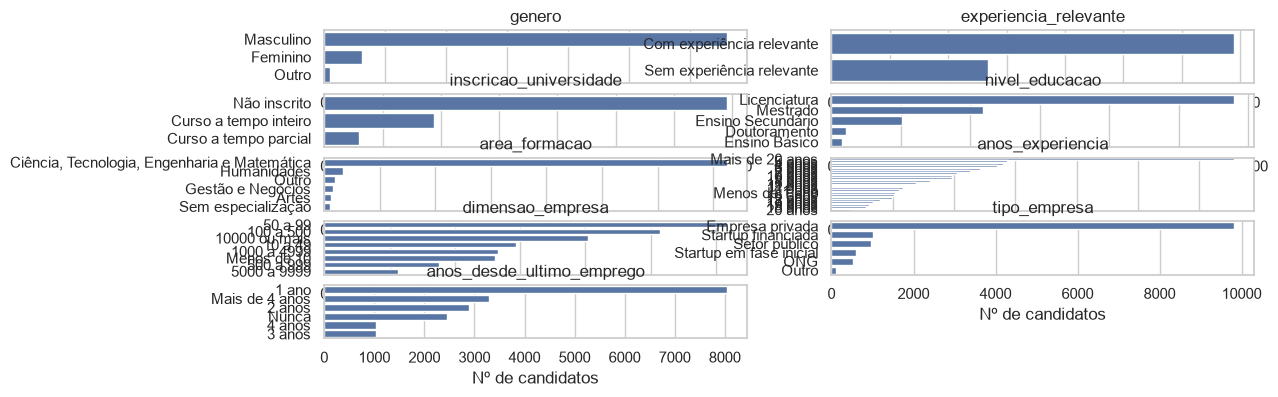

Figura guardada em: Data\analytics\top10_cidades.png


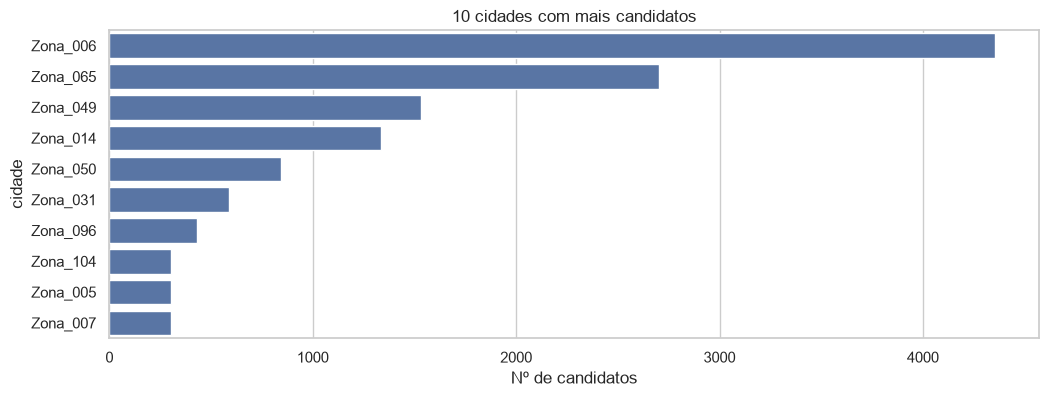

In [26]:
# tabelas de frequências (inclui os nulos como categoria, para se verem)
for col in cat_cols:
    freq = pd.DataFrame({
        "numero": df[col].value_counts(dropna=False),
        "%": (df[col].value_counts(dropna=False, normalize=True) * 100).round(2)
    })
    print(f"\n{col}: {df[col].nunique()} categorias | moda: {df[col].mode()[0]}")
    display(freq.head(10)) # cidade tem 123 categorias: mostrar só as 10 mais frequentes

# countplots (todas menos cidade)
cols_graf = [c for c in cat_cols if c != "cidade"]
numero_linhas = int(np.ceil(len(cols_graf) / 2))
fig, axes = plt.subplots(numero_linhas, 2, figsize=(12,4))

for ax, col in zip(axes.flat, cols_graf):
    sns.countplot(y=df[col], order=df[col].value_counts().index, ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")
    ax.set_xlabel("Nº de candidatos")

for ax in axes.flat[len(cols_graf):]:
    ax.set_visible(False)

plt.tight_layout()
guardar_figura("countplots_categoricas")
plt.show()

# cidade: só as 10 mais frequentes
top_cidades = df["cidade"].value_counts().head(10)
plt.figure(figsize=(12, 4))
sns.barplot(x=top_cidades.values, y=top_cidades.index)
plt.title("10 cidades com mais candidatos")
plt.xlabel("Nº de candidatos")
guardar_figura("top10_cidades")
plt.show()

##### Análise e Interpretação

> *Há categorias raras ou dominantes? A cardinalidade é alta?*

**Resposta:**

- 

<hr>

**4.8 [Classificação] Balanceamento da variável-alvo**
- `value_counts()` (absoluto e `normalize=True`) e `countplot` do target.

,numero,%
procura_mudanca_emprego,,
Não,14381,75.07
Sim,4777,24.93


Rácio maioritária/minoritária: 3.0 : 1
Accuracy de prever sempre 'Não': 75.1%
Figura guardada em: Data\analytics\balanceamento_target.png


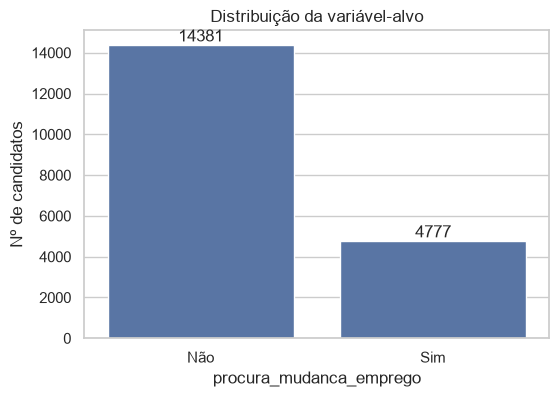

In [27]:
# contagens absolutas e percentagens do target
balanceamento = pd.DataFrame({
    "numero": df[TARGET].value_counts(),
    "%": (df[TARGET].value_counts(normalize=True) * 100).round(2)
})
display(balanceamento)

# rácio entre a classe maioritária e a minoritária
racio = balanceamento["numero"].max() / balanceamento["numero"].min()
print(f"Rácio maioritária/minoritária: {racio:.1f} : 1")

# baseline: prever sempre a classe maioritária
print(f"Accuracy de prever sempre '{balanceamento['numero'].idxmax()}': "
      f"{balanceamento['%'].max():.1f}%")

# countplot do target
plt.figure(figsize=(6, 4))
ax = sns.countplot(x=df[TARGET], order=balanceamento.index)
for container in ax.containers:
    ax.bar_label(container, fmt="%d")
plt.title("Distribuição da variável-alvo")
plt.xlabel(TARGET)
plt.ylabel("Nº de candidatos")
guardar_figura("balanceamento_target")
plt.show()

##### Análise e Interpretação

> *As classes estão equilibradas? Que consequências tem isso para a escolha das métricas e para a divisão treino/teste?*

**Resposta:**

- As classes **não estão equilibradas**: cerca de **75% "Não"** e **25% "Sim"** (rácio de 3 para 1). É um desbalanceamento moderado, não extremo, mas a classe de interesse (quem procura mudar) é a minoritária.
- **Métricas:** a accuracy engana. Um modelo que previsse sempre "Não" teria cerca de 75% de accuracy sem encontrar nenhum candidato recetivo. Como definido na Fase 1, a métrica principal é o **recall da classe "Sim"** com um mínimo de **precision**, complementado pelo **F1-score**, pela **ROC-AUC** e pela **matriz de confusão**.
- **Divisão treino/teste:** usar `stratify=y` para que o treino e o teste mantenham a proporção 75/25. Na validação cruzada, usar `StratifiedKFold`.
- **Tratamento do desbalanceamento:** testar primeiro `class_weight="balanced"`. Se se usar reamostragem (SMOTE, oversampling), aplicá-la **só no treino** (dentro de cada fold, com o Pipeline do `imblearn`). O conjunto de teste mantém sempre a distribuição real.
- **Baselines a superar (Fase 5):** prever sempre "Não" (recall = 0) e prever sempre "Sim" (precision ≈ 0,25).

<hr>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Classes desbalanceadas</div>Se uma classe for muito maior do que a outra (ex.: 80/20), a <b>accuracy engana</b>: prever sempre a classe maioritária já dá 80%. Nesse caso usar <b>precision, recall, F1 e ROC-AUC</b> e <code>stratify=y</code> na divisão treino/teste. Também determina se são precisas técnicas como <code>class_weight</code> ou reamostragem (SMOTE) — M2.03. A reamostragem (SMOTE, oversampling, undersampling) faz-se <b>só no treino</b> e, na validação cruzada, dentro de cada fold (Pipeline do <code>imblearn</code>). Nunca antes da divisão: exemplos sintéticos criados a partir de linhas do teste passariam informação do teste para o treino. O teste mantém sempre a distribuição real.</div>

**4.8 [Regressão] Distribuição da variável-alvo**
- `describe()`, skew e histograma com KDE do target.

In [28]:
### O nosso é classificaçao, portanto o mais provavel é apagar isto?! 

##### Análise e Interpretação

> *Como se distribui o alvo? É assimétrico? Há valores extremos?*

**Resposta:**


<hr>

### 5. Análise bivariada
<hr>

**Variáveis vs Target**
- Classificação: boxplot/violin por classe, médias por grupo, taxa do target por categoria
- Regressão: scatter plot com o target, correlação com o target, boxplot do target por categoria

**Correlação entre variáveis**
- Matriz de correlação e heatmap
- Identificar multicolinearidade (variáveis explicativas fortemente correlacionadas entre si)

**Testes estatísticos (M2.05)** — intervalos de confiança e testes de hipóteses para confirmar as hipóteses da Fase 1.

***Objetivo:*** perceber as relações importantes.

**5.1 [Classificação] Numéricas por classe do target**
- Boxplot (`showmeans=True`) ou violinplot de cada numérica por classe do target.
- Tabela de médias e medianas por classe (`groupby`).

Figura guardada em: Data\analytics\boxplots_numericas_por_target.png


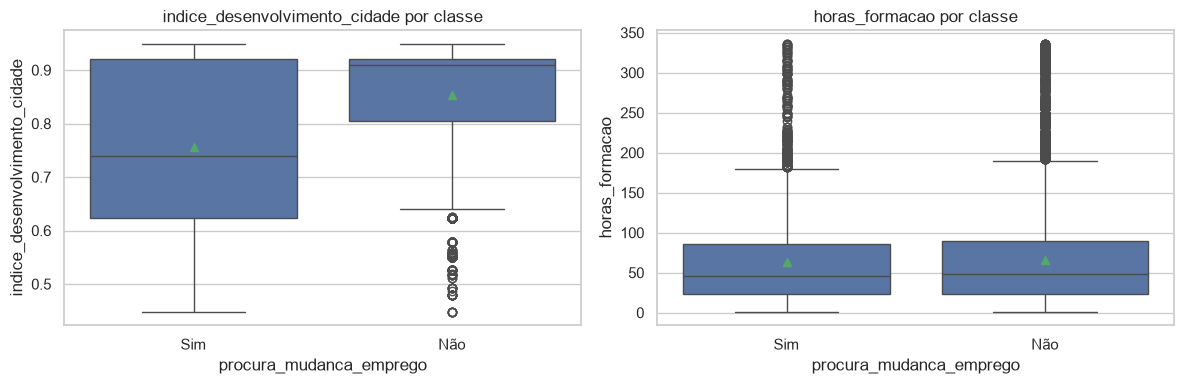

procura_mudanca_emprego                 Não    Sim  diferenca_Sim_Nao
indice_desenvolvimento_cidade mean     0.85   0.76              -0.09
                              median   0.91   0.74              -0.17
horas_formacao                mean    66.11  63.12              -2.99
                              median  48.00  46.00              -2.00

,n_candidatos,taxa_Sim_%
indice_desenvolvimento_cidade,,
"(0.0, 0.6]",725,57.9
"(0.6, 0.7]",3831,49.7
"(0.7, 0.8]",1410,24.7
"(0.8, 0.9]",3549,13.6
"(0.9, 1.0]",9643,16.8


In [29]:
# boxplots de cada numérica por classe do target (média assinalada com triângulo)
ordem_classes = ["Sim", "Não"]
fig, axes = plt.subplots(1, len(num_cols), figsize=(12, 4))

for ax, col in zip(axes, num_cols):
    sns.boxplot(x=df[TARGET], y=df[col], order=ordem_classes, showmeans=True, ax=ax)
    ax.set_title(f"{col} por classe")
    ax.set_xlabel(TARGET)

plt.tight_layout()
guardar_figura("boxplots_numericas_por_target")
plt.show()

# médias e medianas por classe
medidas = df.groupby(TARGET)[num_cols].agg(["mean", "median"]).T.round(2)
medidas["diferenca_Sim_Nao"] = (medidas["Sim"] - medidas["Não"]).round(2)
display(medidas)

# taxa de "Sim" por faixa do índice de desenvolvimento (para ver a forma da relação)
faixas = pd.cut(df["indice_desenvolvimento_cidade"], bins=[0, 0.6, 0.7, 0.8, 0.9, 1.0])
taxa_faixas = pd.DataFrame({
    "n_candidatos": df.groupby(faixas, observed=True)[TARGET].size(),
    "taxa_Sim_%": (df.groupby(faixas, observed=True)[TARGET]
                     .apply(lambda s: (s == "Sim").mean() * 100).round(1))
})
display(taxa_faixas)

##### Análise e Interpretação

> *Que variáveis parecem separar melhor as classes?*

**Resposta:**

- **`indice_desenvolvimento_cidade` separa bem as classes.** Quem procura mudar vive, em média, em cidades menos desenvolvidas: a mediana é **0,74** nos "Sim" contra **0,91** nos "Não" (médias de 0,756 vs 0,853). No boxplot, a caixa dos "Sim" é muito mais larga e desce até 0,62, enquanto a dos "Não" fica concentrada entre 0,80 e 0,92.
- A relação **não é linear**: a taxa de "Sim" é de cerca de **58%** nas cidades com índice ≤ 0,6 e de **50%** entre 0,6 e 0,7, mas cai para **25%** entre 0,7 e 0,8 e fica em **14–17%** acima de 0,8. Há um "salto" por volta de 0,7, e não uma descida gradual. Modelos baseados em árvores captam este tipo de limiar melhor do que uma regressão logística simples.
- **`horas_formacao` quase não separa as classes.** As medianas são praticamente iguais (46 h nos "Sim" vs 48 h nos "Não"), as caixas sobrepõem-se quase por completo e a diferença de médias é de apenas 3 horas. Sozinha, parece ter pouco poder preditivo.
- **Hipóteses da Fase 1:**
  - **H2** (cidades menos desenvolvidas → mais procura de mudança): **suportada** pelos dados.
  - **H3** (mais horas de formação → mais abertura à mudança): **não suportada**. Se alguma coisa, os "Sim" têm ligeiramente *menos* horas.
  - Ambas serão confirmadas com testes estatísticos na secção 5.5.
- **Nota (data leakage):** esta análise é descritiva. Não se escolhem nem se eliminam variáveis com base nela; os limiares das faixas são só para leitura e não devem ser reutilizados na Fase 3.

<hr>

**5.2 [Classificação] Taxa do target por categoria**
- `pd.crosstab(..., normalize="index")` para cada categórica.
- `countplot` com `hue=TARGET` e `barplot` da taxa média do target por categoria.

Taxa global de 'Sim': 24.9%

genero:


procura_mudanca_emprego,Não,Sim,n
genero,,,
Em falta,69.2,30.8,4508
Feminino,73.7,26.3,1238
Outro,73.8,26.2,191
Masculino,77.2,22.8,13221



experiencia_relevante:


procura_mudanca_emprego,Não,Sim,n
experiencia_relevante,,,
Sem experiência relevante,66.2,33.8,5366
Com experiência relevante,78.5,21.5,13792



inscricao_universidade:


...


tipo_empresa:


procura_mudanca_emprego,Não,Sim,n
tipo_empresa,,,
Em falta,61.2,38.8,6140
Outro,76.0,24.0,121
Startup em fase inicial,76.5,23.5,603
Setor público,78.0,22.0,955
ONG,81.4,18.6,521
Empresa privada,81.9,18.1,9817
Startup financiada,86.0,14.0,1001



anos_desde_ultimo_emprego:


procura_mudanca_emprego,Não,Sim,n
anos_desde_ultimo_emprego,,,
Nunca,69.9,30.1,2452
1 ano,73.6,26.4,8040
2 anos,75.9,24.1,2900
3 anos,77.4,22.6,1024
4 anos,77.8,22.2,1029
Mais de 4 anos,81.8,18.2,3290
Em falta,63.6,36.4,423


Figura guardada em: Data\analytics\countplots_categoricas_por_target.png


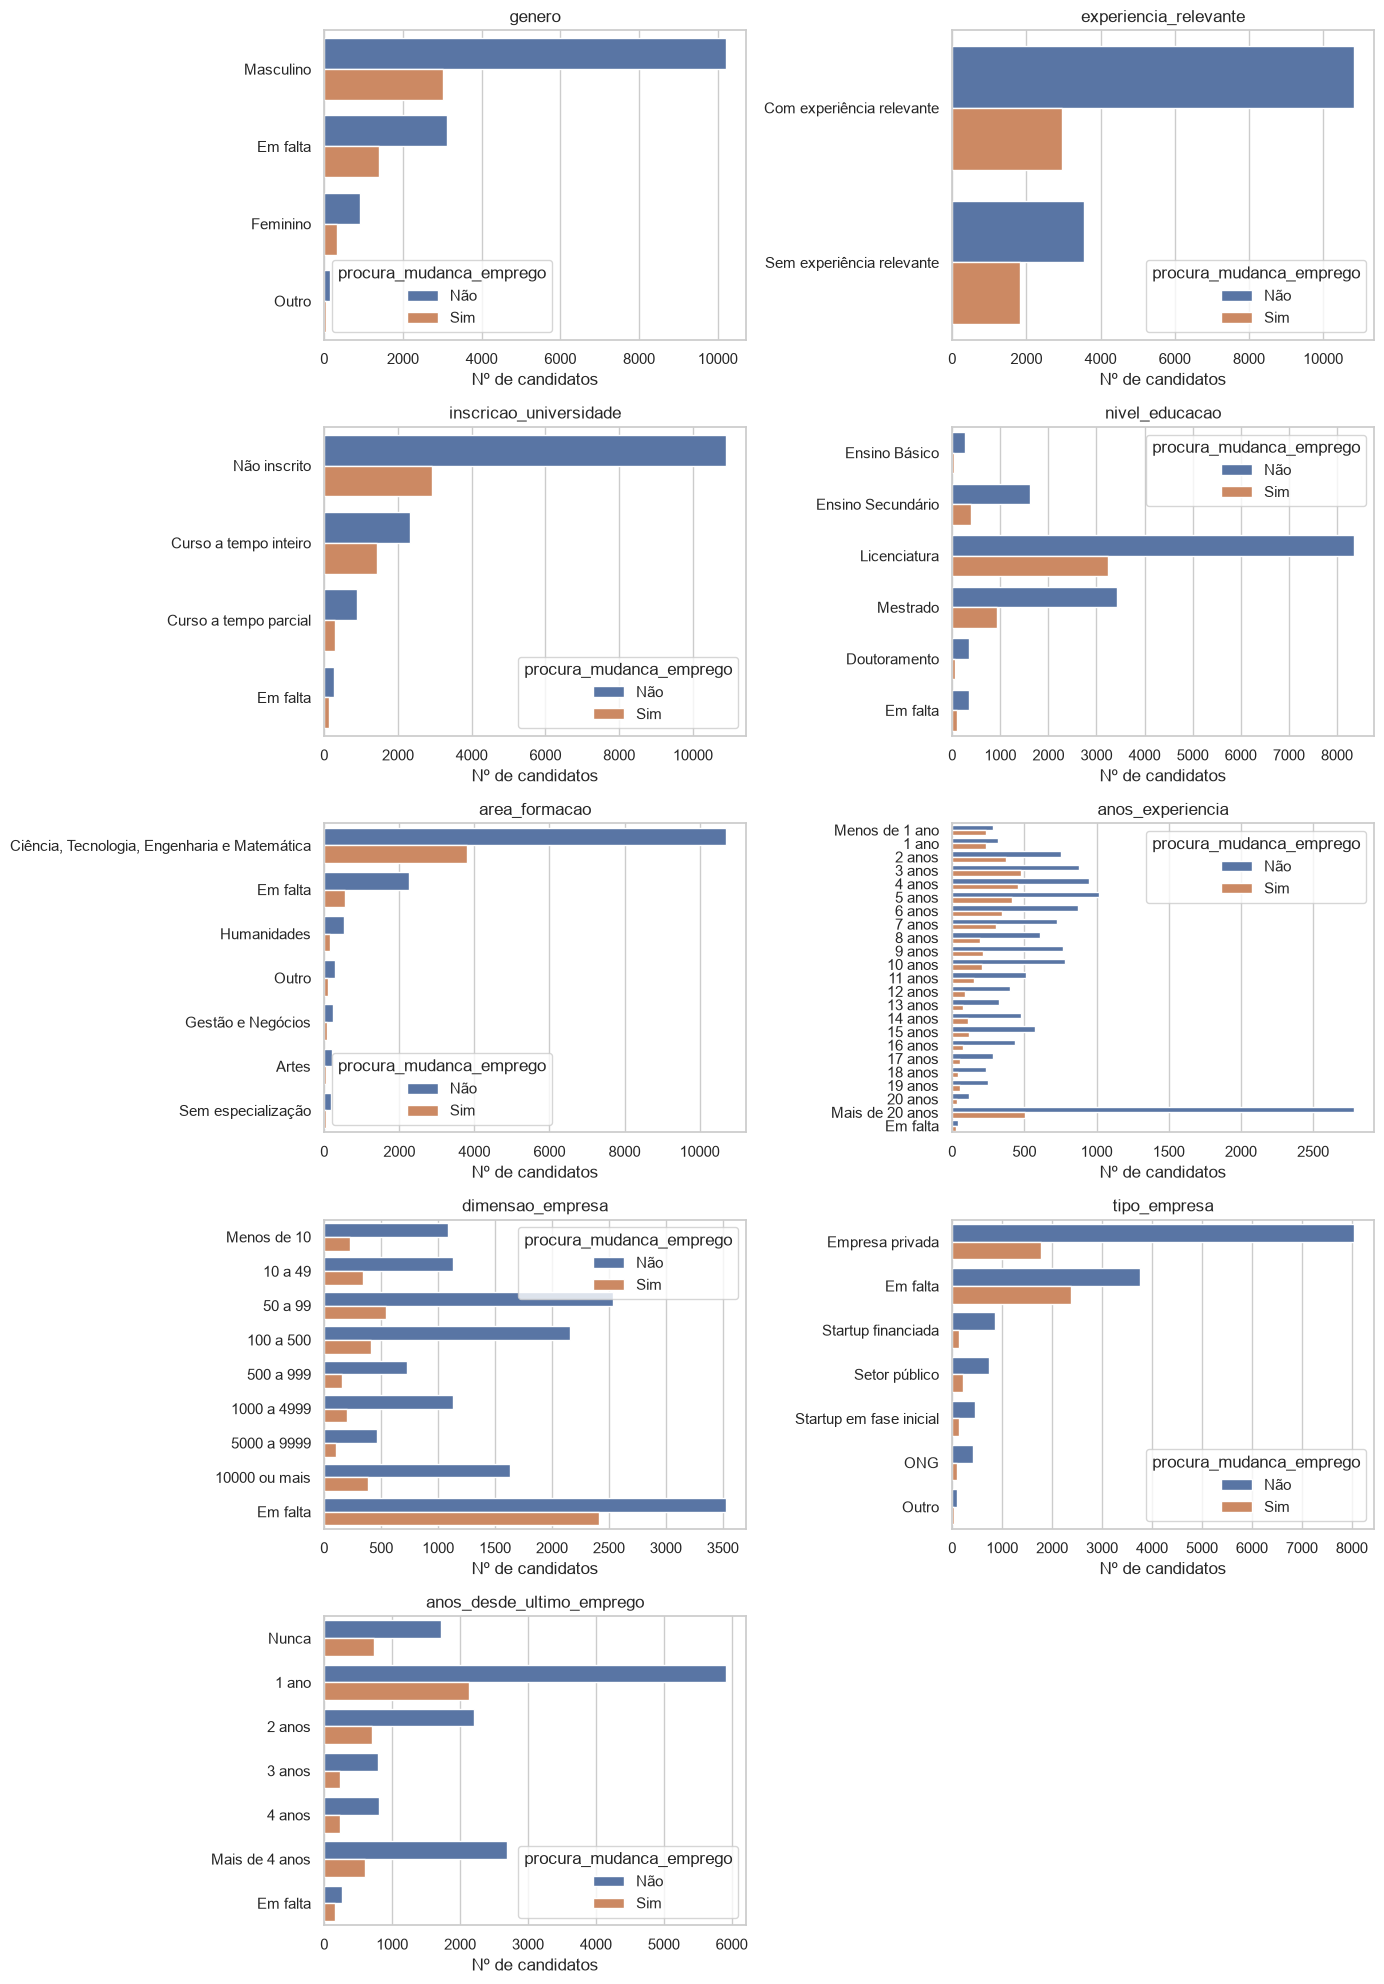

Figura guardada em: Data\analytics\taxa_target_por_categoria.png


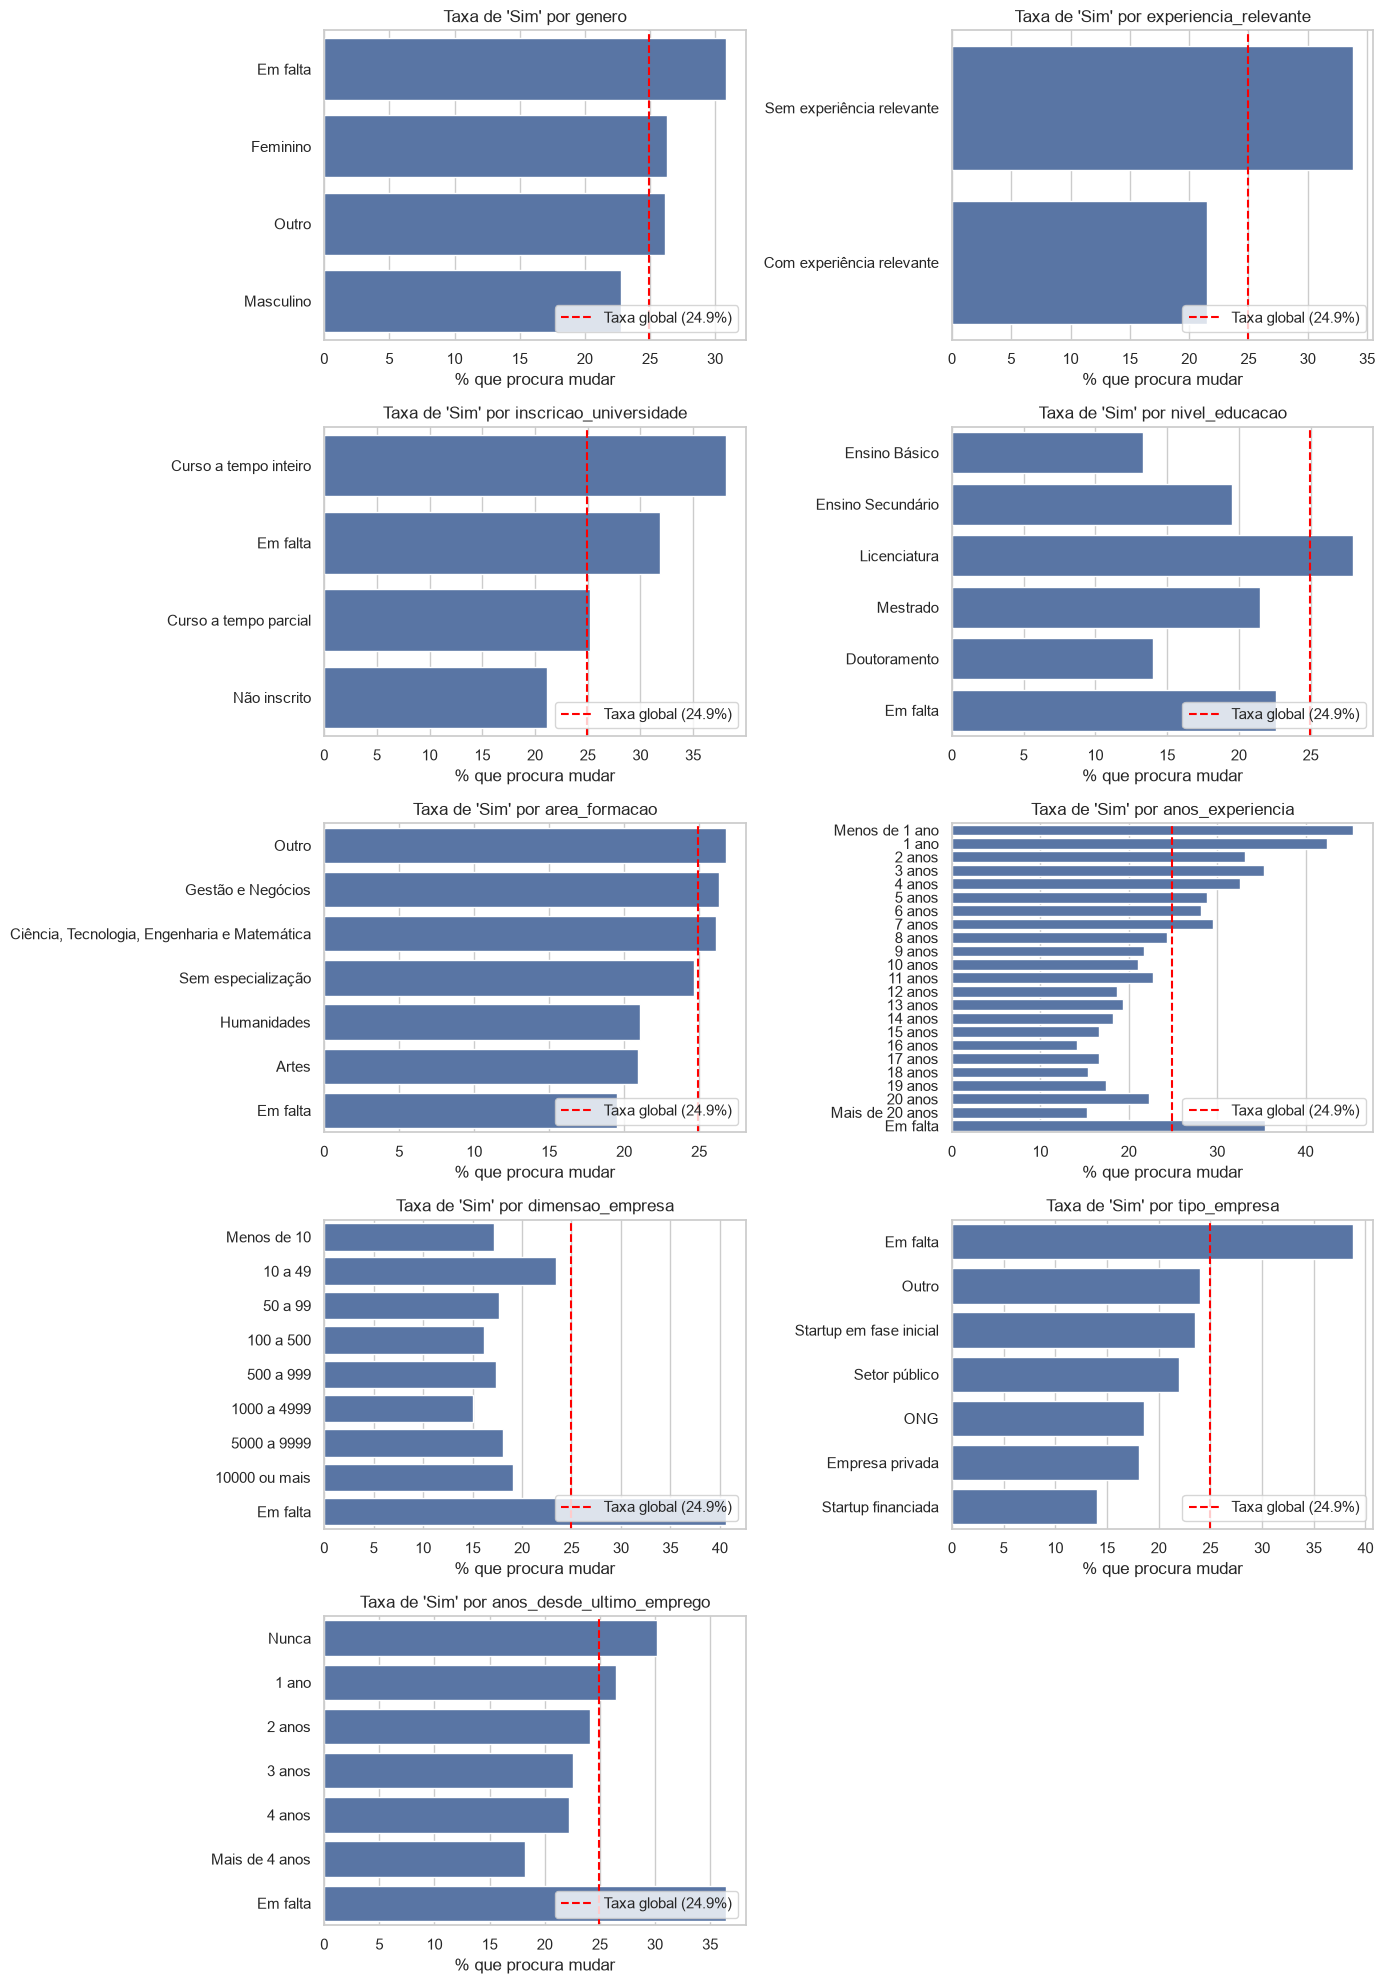

,taxa_Sim_preenchido_%,taxa_Sim_em_falta_%,diferenca_pp
dimensao_empresa,17.9,40.6,22.7
tipo_empresa,18.4,38.8,20.4
anos_desde_ultimo_emprego,24.7,36.4,11.7
anos_experiencia,24.9,35.4,10.5
genero,23.1,30.8,7.7
inscricao_universidade,24.8,31.9,7.1
nivel_educacao,25.0,22.6,-2.4
area_formacao,25.9,19.5,-6.4


,n,taxa_Sim_pct
cidade,,
Zona_012,247,59.5
Zona_065,2702,59.1
Zona_102,280,26.4
Zona_003,275,23.6
Zona_050,845,23.6
Zona_006,4355,21.3
Zona_005,304,17.1
Zona_100,266,14.7
Zona_096,431,13.2


In [31]:
# taxa global de "Sim" (referência para comparar cada categoria)
taxa_global = (df[TARGET] == "Sim").mean() * 100
print(f"Taxa global de 'Sim': {taxa_global:.1f}%")

# ordem natural das ordinais (para os gráficos ficarem legíveis)
ordens = {
    "nivel_educacao": ["Ensino Básico", "Ensino Secundário", "Licenciatura", "Mestrado", "Doutoramento", "Em falta"],
    "anos_experiencia": ["Menos de 1 ano", "1 ano"] + [f"{i} anos" for i in range(2, 21)] + ["Mais de 20 anos", "Em falta"],
    "dimensao_empresa": ["Menos de 10", "10 a 49", "50 a 99", "100 a 500", "500 a 999",
                        "1000 a 4999", "5000 a 9999", "10000 ou mais", "Em falta"],
    "anos_desde_ultimo_emprego": ["Nunca", "1 ano", "2 anos", "3 anos", "4 anos", "Mais de 4 anos", "Em falta"],
}

# nulos como categoria própria "Em falta" (só para a análise; não altera o df)
cols_cat = [c for c in cat_cols if c != "cidade"]
dados = df[cols_cat].fillna("Em falta")
dados[TARGET] = df[TARGET]

# crosstab normalizado por linha para cada categórica
for col in cols_cat:
    tabela = pd.crosstab(dados[col], dados[TARGET], normalize="index").mul(100).round(1)
    tabela["n"] = dados[col].value_counts()
    tabela = tabela.reindex(ordens.get(col, tabela.sort_values("Sim", ascending=False).index))
    print(f"\n{col}:")
    display(tabela)

# countplot com hue=TARGET para cada categórica
numero_linhas = int(np.ceil(len(cols_cat) / 2))
fig, axes = plt.subplots(numero_linhas, 2, figsize=(14, 4 * numero_linhas))
for ax, col in zip(axes.flat, cols_cat):
    ordem = ordens.get(col, dados[col].value_counts().index)
    sns.countplot(y=dados[col], hue=dados[TARGET], order=ordem, hue_order=["Não", "Sim"], ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")
    ax.set_xlabel("Nº de candidatos")
for ax in axes.flat[len(cols_cat):]:
    ax.set_visible(False)
plt.tight_layout()
guardar_figura("countplots_categoricas_por_target")
plt.show()

# barplot da taxa de "Sim" por categoria, com a taxa global como referência
dados["Sim"] = (dados[TARGET] == "Sim").astype(int) * 100
fig, axes = plt.subplots(numero_linhas, 2, figsize=(14, 4 * numero_linhas))
for ax, col in zip(axes.flat, cols_cat):
    ordem = ordens.get(col, dados.groupby(col)["Sim"].mean().sort_values(ascending=False).index)
    sns.barplot(x=dados["Sim"], y=dados[col], order=ordem, errorbar=None, ax=ax)
    ax.axvline(taxa_global, color="red", linestyle="--", label=f"Taxa global ({taxa_global:.1f}%)")
    ax.set_title(f"Taxa de 'Sim' por {col}")
    ax.set_ylabel("")
    ax.set_xlabel("% que procura mudar")
    ax.legend(loc="lower right")
for ax in axes.flat[len(cols_cat):]:
    ax.set_visible(False)
plt.tight_layout()
guardar_figura("taxa_target_por_categoria")
plt.show()

# H6 / Q3: a ausência de valor está associada ao target?
cols_com_nulos = [c for c in df.columns if df[c].isnull().any()]
taxa_nulos = pd.DataFrame({
    "taxa_Sim_preenchido_%": [(df.loc[df[c].notnull(), TARGET] == "Sim").mean() * 100 for c in cols_com_nulos],
    "taxa_Sim_em_falta_%": [(df.loc[df[c].isnull(), TARGET] == "Sim").mean() * 100 for c in cols_com_nulos],
}, index=cols_com_nulos).round(1)
taxa_nulos["diferenca_pp"] = taxa_nulos["taxa_Sim_em_falta_%"] - taxa_nulos["taxa_Sim_preenchido_%"]
display(taxa_nulos.sort_values("diferenca_pp", ascending=False))

# cidade: taxa de "Sim" nas cidades com pelo menos 200 candidatos
taxa_cidade = (df.groupby("cidade")[TARGET]
                .agg(n="size", taxa_Sim_pct=lambda s: (s == "Sim").mean() * 100)
                .query("n >= 200").sort_values("taxa_Sim_pct", ascending=False).round(1))
display(taxa_cidade)

##### Análise e Interpretação

> *Que categorias têm taxas muito diferentes? Confirma alguma hipótese da Fase 1?*

**Resposta:**

A taxa global de "Sim" é de **24,9%** e serve de referência para cada categoria.

- **`anos_experiencia` é a variável com o padrão mais claro:** a taxa desce de forma quase contínua, de **45%** (menos de 1 ano) e **42%** (1 ano) para **15%** (mais de 20 anos). Quem está no início da carreira procura muito mais mudar. → **H4 confirmada.**
- **`experiencia_relevante`:** **34%** sem experiência relevante vs **21,5%** com experiência relevante. → **H1 confirmada.**
- **`inscricao_universidade`:** quem está num **curso a tempo inteiro** tem uma taxa de **38%**, contra 21% de quem não está inscrito. Faz sentido: são sobretudo estudantes à procura do primeiro emprego ou de um emprego melhor.
- **`nivel_educacao`:** os licenciados têm a taxa mais alta (**28%**); doutorados (14%) e Ensino Básico (13%) as mais baixas. A relação **não é monótona**: não basta "mais educação → menos procura".
- **`tipo_empresa` e `dimensao_empresa`:** entre as categorias preenchidas, as diferenças são pequenas (14–24%). As startups em fase inicial (23,5%) e as empresas de 10 a 49 pessoas (23,4%) ficam um pouco acima, mas as startups financiadas têm a taxa mais baixa (14%). → **H5 só parcialmente suportada**: o efeito do tipo e da dimensão da empresa é fraco.
- **`genero`, `area_formacao` e `anos_desde_ultimo_emprego`:** diferenças moderadas. Quem "Nunca" teve emprego anterior tem 30%; "Mais de 4 anos", 18%.
- **Valores em falta (H6 / Q3) — a descoberta mais forte:**
  - `dimensao_empresa` em falta: **40,6%** de "Sim" vs **17,9%** quando preenchida (+22,7 p.p.);
  - `tipo_empresa` em falta: **38,8%** vs **18,4%** (+20,4 p.p.);
  - `genero` em falta: **30,8%** vs **23,1%** (+7,7 p.p.).
  - A ausência de valor **é informativa** (não é MCAR). Provavelmente quem não indica empresa não tem emprego atual e está mais disponível. → **H6 confirmada.** Na Fase 3, os nulos devem ser tratados como categoria própria ("Desconhecido") ou com uma variável indicadora, e **não** imputados com a moda (o que apagaria este sinal).
  - Exceção: `area_formacao` em falta tem uma taxa *mais baixa* (19,5%), porque os nulos correspondem a candidatos com Ensino Básico/Secundário, que já têm taxas baixas.
- **`cidade`:** entre as cidades com pelo menos 200 candidatos, as taxas vão de cerca de **9%** (Zona_007, Zona_014) a cerca de **59%** (Zona_065, Zona_012). A diferença é muito grande, mas grande parte dela já é explicada pelo `indice_desenvolvimento_cidade` (secção 5.1). Com 123 categorias, a cidade não deve entrar como one-hot; o índice já resume a informação relevante.
- **Nota (data leakage):** estas taxas são descritivas. Na Fase 3, qualquer codificação baseada no target (ex.: *target encoding* da cidade) tem de ser calculada só no treino.

<hr>

**5.1 [Regressão] Numéricas vs target**
- Scatter com reta (`sns.regplot`) de cada numérica contra o target.
- Tabela com as correlações de Pearson e Spearman com o target.

In [ ]:
## Novamente, regressao, é para apagar isto

##### Análise e Interpretação

> *Que variáveis têm relação mais forte com o alvo? A relação é linear?*

**Resposta:**

- 

<hr>

**5.2 [Regressão] Target por categoria**
- Contagem, média e mediana do target por categoria (`groupby`) e boxplot.

In [ ]:
## Same

##### Análise e Interpretação

> *O valor do alvo muda muito entre categorias?*

**Resposta:**

- 

<hr>

**5.3 Matriz de correlação**
- Heatmap da matriz de correlação das numéricas (e do target, se for numérico) com `annot=True`.

Figura guardada em: Data\analytics\matriz_correlacao.png


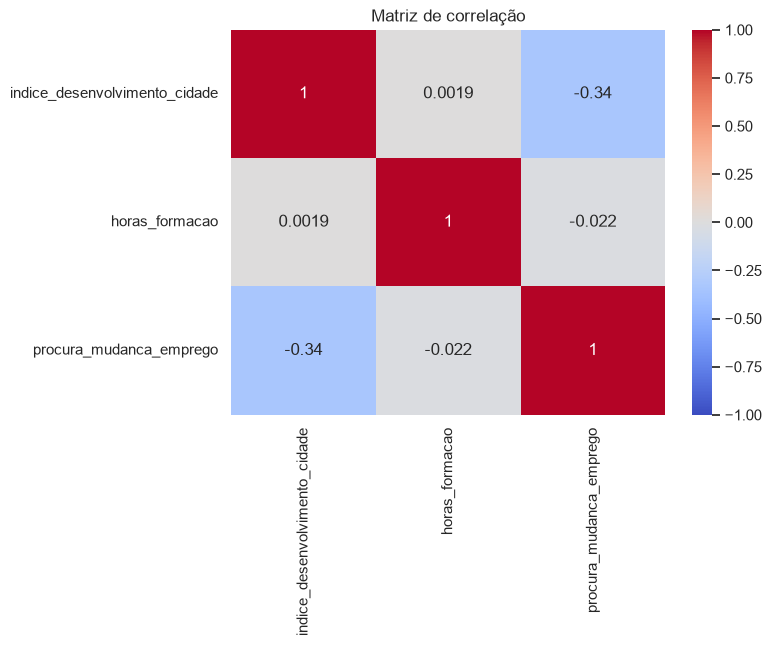

In [34]:
# numéricas + target convertido em 0/1 (Sim = 1), numa cópia para não alterar o df
corr_df = df[num_cols].copy()
corr_df[TARGET] = (df[TARGET] == "Sim").astype(int)

matriz_corr = corr_df.corr()

plt.figure(figsize=(7, 5))
sns.heatmap(matriz_corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlação")
guardar_figura("matriz_correlacao")
plt.show()

##### Análise e Interpretação

> *Que variáveis estão mais correlacionadas com o alvo? E entre si?*

**Resposta:**

- Para o target entrar na matriz, foi convertido em número (Sim = 1, Não = 0).
- **Correlação com o alvo:**
  - `indice_desenvolvimento_cidade`: **r = −0,34**, uma correlação negativa **moderada**. Quanto mais desenvolvida a cidade, menor a procura de mudança de emprego (confirma a 5.1 e a **H2**);
  - `horas_formacao`: **r = −0,02**, praticamente nula. As horas de formação não têm relação linear com a procura de mudança (coerente com a **H3** não suportada na 5.1).
- **Correlação entre si:** `indice_desenvolvimento_cidade` e `horas_formacao` têm **r = 0,00**. São independentes, por isso não há redundância entre as duas.
- **Atenção:** a correlação só mede relações **lineares** entre variáveis numéricas. As categóricas (experiência, empresa, nulos…) não entram nesta matriz, e a sua relação com o alvo já foi analisada na 5.2.

<hr>


**5.4 Multicolinearidade**
- Listar os pares de variáveis explicativas com |r| > 0,8.

In [ ]:
# correlação entre as variáveis explicativas (sem o target)
corr_explicativas = df[num_cols].corr()
display(corr_explicativas.round(2))

# True = par com |r| > 0,8 (a diagonal é sempre True: é a variável com ela própria)
display(corr_explicativas.abs() > 0.8)


## Nos aqui nao vamos ter nenhum |r| > 0.8, nao sei se apagamos este notebook ou ficamos p ara dizer que nao há.

,indice_desenvolvimento_cidade,horas_formacao
indice_desenvolvimento_cidade,1.0,0.0
horas_formacao,0.0,1.0


,indice_desenvolvimento_cidade,horas_formacao
indice_desenvolvimento_cidade,True,False
horas_formacao,False,True


##### Análise e Interpretação

> *Há variáveis redundantes? Qual manteriam e porquê?*

**Resposta:**

- **Não há variáveis redundantes:** `indice_desenvolvimento_cidade` e `horas_formacao` têm **r = 0,00**, muito abaixo do limite de 0,8. Mantêm-se as duas.
- Fora da matriz, `cidade` e `indice_desenvolvimento_cidade` são redundantes (cada cidade tem sempre o mesmo índice). Na Fase 3 fica o **índice**, porque resume a cidade numa só coluna numérica, em vez de 123 categorias.

<hr>


<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Correlação usa-se de forma <b>crítica</b>: mede apenas relação <b>linear</b> (Pearson) ou monótona (Spearman), é sensível a outliers e <b>correlação não implica causalidade</b>.</div>

#### 5.5 Testes estatísticos (opcional, valorizado)

| Situação | Teste | Hipótese nula (H0) |
|---|---|---|
| Numérica vs target binário | teste t (Welch) / Mann-Whitney | as médias/distribuições são iguais nas duas classes |
| Numérica vs target com 3+ classes | ANOVA / Kruskal-Wallis | as médias são iguais em todos os grupos |
| Categórica vs target categórico | Qui-quadrado | as variáveis são independentes |
| Categórica vs target numérico | teste t (2 grupos) / ANOVA (3+ grupos) | a média do target é igual em todos os grupos |
| Numérica vs target numérico | correlação de Pearson / Spearman (secção 5.1) | — |

Regra de decisão: se **p-value < 0,05**, rejeita-se H0 (a diferença/relação é estatisticamente significativa).

Cuidados (M2.05): o t-test pressupõe normalidade (ou n grande) → usar `equal_var=False` (Welch); a ANOVA diz que *pelo menos um* grupo difere, mas não qual; o qui-quadrado exige frequências esperadas ≥ 5. Alternativas não paramétricas: **Mann-Whitney**, **Kruskal-Wallis**, **Spearman**.

**5.5.1 [Classificação] Intervalos de confiança (M2.05)**
- Para cada numérica e cada classe: n, média e IC 95% (`stats.t.interval` com `stats.sem`).

In [ ]:
# IC 95% da média de cada numérica, em cada classe do target
linhas = []
for col in num_cols:
    for classe in ["Não", "Sim"]:
        valores = df.loc[df[TARGET] == classe, col]
        media = valores.mean()
        ic_inf, ic_sup = stats.t.interval(0.95, len(valores) - 1, loc=media, scale=stats.sem(valores))
        linhas.append({"variavel": col, "classe": classe, "n": len(valores),
                       "media": round(media, 3), "IC95_inf": round(ic_inf, 3), "IC95_sup": round(ic_sup, 3)})

display(pd.DataFrame(linhas))

##### Análise e Interpretação

> *Os intervalos das classes sobrepõem-se? O que isso sugere?*

**Resposta:**

- **`indice_desenvolvimento_cidade`:** os intervalos **não se sobrepõem**. Média de **0,853** [0,851; 0,855] nos "Não" vs **0,756** [0,752; 0,760] nos "Sim". A diferença é grande face à largura dos intervalos, o que sugere uma diferença real entre as classes (confirmada na 5.5.2).
- **`horas_formacao`:** os intervalos **também não se sobrepõem**, mas ficam muito próximos. Média de **66,1 h** [65,1; 67,1] nos "Não" vs **63,1 h** [61,5; 64,7] nos "Sim". A diferença é de apenas **3 horas**.
- Os intervalos são muito estreitos porque as amostras são grandes (14 381 e 4 777 candidatos): com muitos dados, a média é estimada com muita precisão, e até diferenças pequenas deixam de se sobrepor. Não se sobrepor **não quer dizer** que a diferença seja importante na prática.

<hr>


**5.5.2 [Classificação] Testes de diferença de médias (M2.05)**
- 2 classes: `stats.ttest_ind(..., equal_var=False)`; 3+ classes: `stats.f_oneway`.
- Tabela com estatística, p-value e conclusão (α = 0,05).

In [ ]:
# 2 classes -> t-test de Welch (equal_var=False) + Mann-Whitney (não paramétrico, porque as numéricas não são normais - 4.4)
linhas = []
for col in num_cols:
    grupo_nao = df.loc[df[TARGET] == "Não", col]
    grupo_sim = df.loc[df[TARGET] == "Sim", col]

    t, p_t = stats.ttest_ind(grupo_nao, grupo_sim, equal_var=False)
    u, p_u = stats.mannwhitneyu(grupo_nao, grupo_sim)

    linhas.append({"variavel": col,
                   "t_Welch": round(t, 2), "p_value_t": p_t,
                   "p_value_MannWhitney": p_u,
                   "conclusao": "diferença significativa" if p_t < 0.05 else "sem diferença significativa"})

display(pd.DataFrame(linhas))

##### Análise e Interpretação

> *Em que variáveis a diferença entre classes é estatisticamente significativa? Os pressupostos do teste verificam-se?*

**Resposta:**

- **`indice_desenvolvimento_cidade`:** diferença **significativa** nos dois testes (t = 43,3; p ≈ 0). Rejeita-se H0: o índice médio é diferente entre quem procura e quem não procura mudar. → **H2 confirmada.**
- **`horas_formacao`:** resultado **no limite**:
  - t-test de Welch: p = 0,002 → significativo;
  - Mann-Whitney: p = 0,051 → **não** significativo (por pouco).
  - Os dois testes discordam porque o t-test compara **médias**, que são puxadas pelos outliers da cauda direita (até 336 h), enquanto o Mann-Whitney compara as **distribuições** (ordens), e as medianas são quase iguais (46 h vs 48 h).
  - Mesmo que se considere significativa, a diferença é de apenas 3 horas: **estatisticamente detetável, mas sem relevância prática**. → **H3 não suportada** (e, se alguma coisa, os "Sim" têm *menos* horas, não mais).
- **Pressupostos:**
  - O t-test pressupõe normalidade, e nenhuma das numéricas é normal (Shapiro-Wilk, 4.4). Mas com amostras tão grandes o t-test continua válido (teorema do limite central), e usou-se `equal_var=False` (Welch) porque as variâncias das classes são diferentes.
  - Por isso juntou-se o **Mann-Whitney**, que não exige normalidade. Neste caso, é o mais fiável para `horas_formacao`, por causa da assimetria.

<hr>


**5.5.3 [Classificação] Qui-quadrado (M2.05)**
- Para cada categórica: `stats.chi2_contingency(pd.crosstab(...))` — estatística, graus de liberdade e p-value.

In [ ]:
# qui-quadrado de independência: cada categórica vs target
linhas = []
for col in cat_cols:
    tabela = pd.crosstab(df[col], df[TARGET])
    chi2, p, gl, esperadas = stats.chi2_contingency(tabela)
    linhas.append({"variavel": col, "chi2": round(chi2, 1), "graus_liberdade": gl, "p_value": p,
                   "min_freq_esperada": round(esperadas.min(), 1),
                   "conclusao": "associada ao target" if p < 0.05 else "independente do target"})

display(pd.DataFrame(linhas).sort_values("chi2", ascending=False))

##### Análise e Interpretação

> *Que categóricas estão associadas ao alvo?*

**Resposta:**

- **Todas as categóricas têm p < 0,05**: rejeita-se H0 (independência) em todas, ou seja, todas estão associadas à procura de mudança de emprego.
- Mas a **força** da associação é muito diferente. Pelo valor do qui-quadrado (a comparar com cuidado, porque depende dos graus de liberdade):
  - **muito forte:** `anos_experiencia` (χ² = 702), `inscricao_universidade` (455), `experiencia_relevante` (315). → **H1 e H4 confirmadas**;
  - **moderada:** `nivel_educacao` (166), `anos_desde_ultimo_emprego` (133);
  - **fraca:** `dimensao_empresa` (46), `tipo_empresa` (35). → **H5 confirmada estatisticamente, mas com efeito fraco** (como na 5.2);
  - **muito fraca:** `area_formacao` (12; p = 0,03) e `genero` (9; p = 0,01). São significativas sobretudo porque a amostra é grande.
- **Pressuposto (frequências esperadas ≥ 5):** verifica-se em todas **exceto `cidade`** (mínimo de 0,2), porque há cidades com muito poucos candidatos. O resultado da cidade (χ² = 2999) **não é fiável** tal como está; teria de se agrupar as cidades pequenas numa categoria "Outras". De qualquer forma, a decisão é usar o `indice_desenvolvimento_cidade` em vez da cidade (5.4).
- **Nota:** o `pd.crosstab` ignora os nulos, por isso este teste não avalia a **H6**. O efeito dos valores em falta foi analisado na 5.2.

<hr>


**5.5 [Regressão] O alvo difere entre grupos? (M2.05)**
- Para cada categórica: t-test de Welch (2 grupos) ou ANOVA (3+ grupos) sobre o target.

##### Análise e Interpretação

> *Que categóricas influenciam significativamente o valor do alvo?*

**Resposta:**

- **Não se aplica.** O target é categórico (Sim / Não); a relação entre as categóricas e o alvo foi testada com o qui-quadrado na 5.5.3.

<hr>


### 6. Análise multivariada
<hr>

**Exploração conjunta de múltiplas variáveis**
- Pairplot (com `hue=target`, se classificação)
- Scatter plots com `hue` / `size` para ver 3 ou 4 variáveis em simultâneo
- Tabelas dinâmicas (duas categóricas vs target)
- Relações não lineares visíveis? Padrões ou agrupamentos naturais? Classes separáveis?

***Objetivo:*** identificar padrões complexos e perceber como as variáveis interagem entre si.

**6.1 Pairplot**
- `sns.pairplot` com as principais numéricas (até 6) e `hue=TARGET` em classificação.

Figura guardada em: Data\analytics\pairplot.png


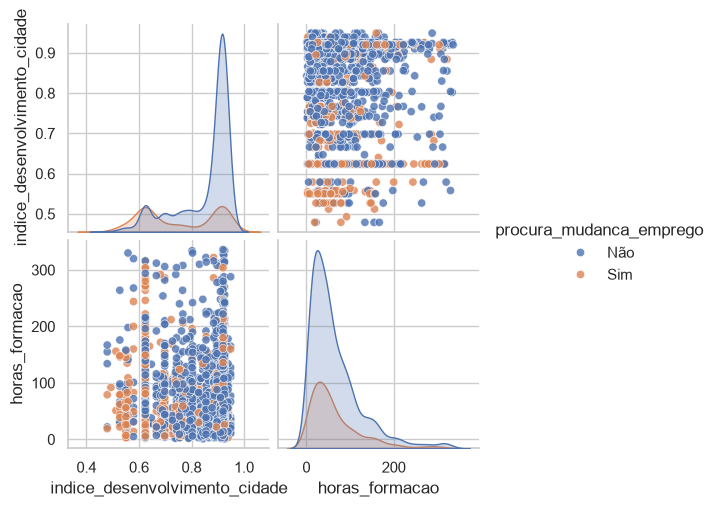

In [40]:
# amostra de 3000 candidatos para o gráfico ficar legível e rápido
amostra = df[num_cols + [TARGET]].sample(3000, random_state=RANDOM_STATE)

sns.pairplot(amostra, hue=TARGET, hue_order=["Não", "Sim"], plot_kws={"alpha": 0.8})
guardar_figura("pairplot")
plt.show()

##### Análise e Interpretação

> *Há pares de variáveis que separam bem as classes ou relações não lineares?*

**Resposta:**

- Usou-se uma amostra de 3000 candidatos para o gráfico ficar legível (com 19 158 pontos sobrepunham-se todos).
- **Diagonal (distribuições por classe):**
  - `indice_desenvolvimento_cidade`: os "Não" concentram-se no pico de 0,92, enquanto os "Sim" têm um pico próprio por volta de 0,62. É a variável que melhor separa as classes;
  - `horas_formacao`: as duas curvas têm a mesma forma e o mesmo pico, só muda a altura (há mais "Não"). Não separa as classes.
- **Fora da diagonal (scatter):** não há nenhuma relação entre as duas variáveis (nuvem sem forma, r = 0,00). Os pontos formam **faixas verticais**, porque o índice só toma um valor por cidade.
- Nenhum par separa as classes por completo: há "Sim" e "Não" misturados em toda a parte.

<hr>


**6.2 Scatter com hue**
- Scatter de duas numéricas colorido pelo target (ou por uma categórica, em clustering).

Figura guardada em: Data\analytics\scatter_indice_horas.png


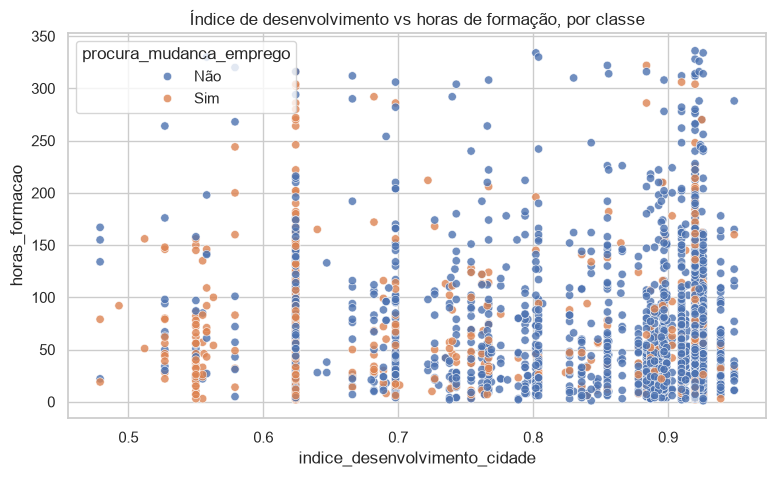

In [41]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=amostra, x="indice_desenvolvimento_cidade", y="horas_formacao",
                hue=TARGET, hue_order=["Não", "Sim"], alpha=0.8)
plt.title("Índice de desenvolvimento vs horas de formação, por classe")
guardar_figura("scatter_indice_horas")
plt.show()

##### Análise e Interpretação

> *O que se aprende ao ver três variáveis ao mesmo tempo?*

**Resposta:**

- Vendo índice, horas e target ao mesmo tempo, percebe-se que a separação acontece **só no eixo horizontal (índice)**:
  - à **esquerda** (índice < 0,7), sobretudo na faixa de 0,62, há muitos pontos laranja ("Sim");
  - à **direita** (índice ≈ 0,9), predominam os azuis ("Não").
- No **eixo vertical (horas)** não há padrão: em cada faixa do índice, os "Sim" e os "Não" aparecem com poucas e com muitas horas.
- Conclusão: as horas de formação **não acrescentam** separação ao índice. Mesmo assim, as classes continuam bastante misturadas, por isso o modelo vai precisar das categóricas (experiência, inscrição, nulos da empresa…) para separar melhor.

<hr>


**6.3 [Classificação] Duas categóricas vs target**
- `pivot_table` com a taxa média do target cruzando duas categóricas e heatmap.

inscricao_universidade,Curso a tempo inteiro,Curso a tempo parcial,Não inscrito
experiencia_relevante,,,
Com experiência relevante,33.1,21.2,19.8
Sem experiência relevante,41.2,33.9,27.4


Figura guardada em: Data\analytics\pivot_experiencia_universidade.png


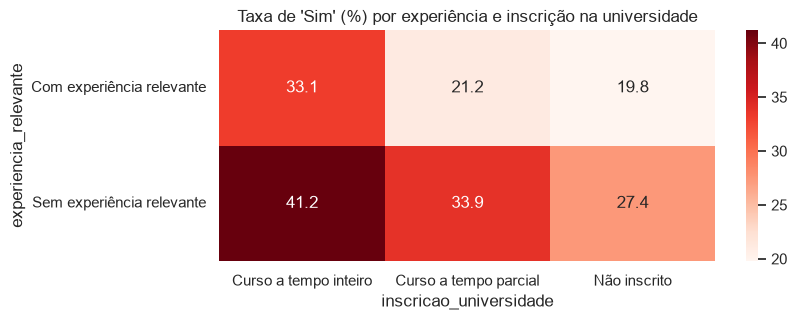

In [42]:
# coluna auxiliar: 1 = procura mudar (a média dá a taxa de "Sim")
df_aux = df.copy()
df_aux["procura_sim"] = (df_aux[TARGET] == "Sim").astype(int)

pivot = pd.pivot_table(df_aux, values="procura_sim", index="experiencia_relevante",
                       columns="inscricao_universidade", aggfunc="mean")
display((pivot * 100).round(1))

plt.figure(figsize=(8, 3))
sns.heatmap(pivot * 100, annot=True, fmt=".1f", cmap="Reds")
plt.title("Taxa de 'Sim' (%) por experiência e inscrição na universidade")
guardar_figura("pivot_experiencia_universidade")
plt.show()

##### Análise e Interpretação

> *Há combinações de categorias com comportamentos muito diferentes (interações)?*

**Resposta:**

Taxa de "Sim" (%) por combinação de `experiencia_relevante` e `inscricao_universidade`:

| | Tempo inteiro | Tempo parcial | Não inscrito |
|---|---|---|---|
| **Com experiência relevante** | 33,1 | 21,2 | **19,8** |
| **Sem experiência relevante** | **41,2** | 33,9 | 27,4 |

- A combinação com mais procura é **sem experiência relevante + curso a tempo inteiro (41%)**; a com menos procura é **com experiência relevante + não inscrito (20%)**. A diferença entre os dois extremos é de cerca de **21 pontos percentuais**, mais do que cada variável mostra sozinha na 5.2.
- Os dois efeitos **somam-se**: em todas as colunas, "sem experiência" tem uma taxa mais alta do que "com experiência", e em ambas as linhas o "tempo inteiro" tem a taxa mais alta. Não há uma interação forte (o efeito de uma variável não muda de sentido conforme a outra).
- Interpretação de negócio: o perfil mais recetivo a uma proposta é o de um **estudante a tempo inteiro, ainda sem experiência na área**, que está a entrar no mercado de trabalho.

<hr>


**6.4 Visão em 2D com PCA**
- Normalizar as numéricas (`StandardScaler`), projetar em 2 componentes (`PCA`) e fazer um scatter PC1 vs PC2 (colorido pelo target em classificação).

Variância explicada por cada componente: [0.501 0.499]
Figura guardada em: Data\analytics\pca_2d.png


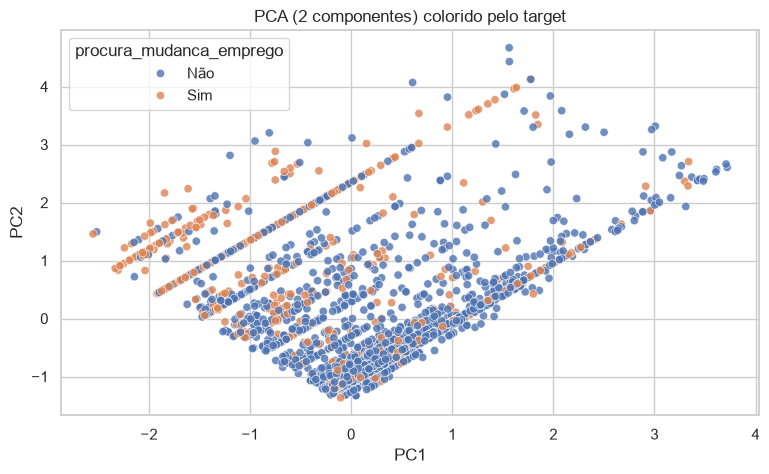

In [43]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# normalizar as numéricas e projetar em 2 componentes
X_num = StandardScaler().fit_transform(df[num_cols])
pca = PCA(n_components=2)
componentes = pca.fit_transform(X_num)
print("Variância explicada por cada componente:", pca.explained_variance_ratio_.round(3))

pca_df = pd.DataFrame(componentes, columns=["PC1", "PC2"])
pca_df[TARGET] = df[TARGET].values

plt.figure(figsize=(9, 5))
sns.scatterplot(data=pca_df.sample(3000, random_state=RANDOM_STATE), x="PC1", y="PC2",
                hue=TARGET, hue_order=["Não", "Sim"], alpha=0.8)
plt.title("PCA (2 componentes) colorido pelo target")
guardar_figura("pca_2d")
plt.show()

##### Análise e Interpretação

> *Existem agrupamentos naturais? As classes parecem separáveis?*

**Resposta:**

- **Limitação:** o dataset só tem 2 numéricas e elas não estão correlacionadas (r = 0,00). Por isso cada componente explica cerca de **50%** da variância (0,501 e 0,499), e o PCA **não reduz nada**: apenas "roda" o gráfico da 6.2 em 45°. Aqui o PCA não traz informação nova.
- **Agrupamentos:** os pontos formam **linhas diagonais**, que correspondem às faixas verticais do índice na 6.2 (cada linha é uma cidade, ou um grupo de cidades com o mesmo índice). Não são grupos naturais de candidatos.
- **Separabilidade:** os "Sim" (laranja) concentram-se mais nas linhas do lado esquerdo e em cima (índice baixo), e os "Não" (azul) na zona de baixo, à direita. Mas as classes **sobrepõem-se muito**, por isso não são separáveis só com as numéricas.
- Conclusão para a modelação: as numéricas sozinhas não chegam. O modelo vai precisar das categóricas, e a relação em "degrau" do índice (5.1) sugere que modelos baseados em **árvores** (Decision Tree, Random Forest) podem funcionar melhor do que modelos lineares.

<hr>


### 7. Síntese da Fase de Data Understanding
<hr>

**Principais padrões identificados**
- Variáveis potencialmente mais relevantes (com evidência: gráfico, correlação, teste)
- Problemas encontrados (missing, duplicados, inconsistências, outliers, desbalanceamento, multicolinearidade)
- Hipóteses da Fase 1 confirmadas / rejeitadas
- Estrutura dos dados (linhas independentes, várias linhas por entidade, ordem temporal) e variáveis com risco de *data leakage*
- Hipóteses iniciais sobre o tipo de modelo adequado (relações lineares ou não lineares?)

#### Decisões para a fase seguinte

| Problema / observação | Evidência (secção) | Decisão para a Fase 3 |
|---|---|---|
| ex.: `Intern_ID` é identificador | 2 | remover das features |
| ex.: `Salary` assimétrica à direita | 4.1 | testar `log1p` / RobustScaler |
| ex.: classes 70/30 | 4.8 | `stratify=y`; avaliar com F1 e ROC-AUC |
| ex.: `Data_Saida` só é conhecida depois do desfecho | 2.3 | remover das features (*data leakage*) |
| | | |

***Objetivo:*** traduzir a análise exploratória em decisões para a Data Preparation.

**Resposta:**

**Variáveis potencialmente mais relevantes**

- `indice_desenvolvimento_cidade`: a numérica mais forte (r = −0,34; t-test p ≈ 0). Relação em "degrau": cerca de 50–58% de "Sim" abaixo de 0,7 e 14–17% acima de 0,8 (5.1, 5.3, 5.5.2).
- `anos_experiencia`: a categórica mais forte (χ² = 702). A taxa de "Sim" desce de 45% (menos de 1 ano) para 15% (mais de 20 anos) (5.2, 5.5.3).
- `inscricao_universidade` (χ² = 455) e `experiencia_relevante` (χ² = 315). Juntas, vão de 20% a 41% de "Sim" (5.2, 6.3).
- **Valores em falta** de `dimensao_empresa` / `tipo_empresa`: 40,6% de "Sim" quando falta vs 17,9% quando está preenchido. É o sinal mais forte de todos (5.2).
- Pouco relevantes: `horas_formacao` (r = −0,02; Mann-Whitney p = 0,051), `genero` e `area_formacao` (associação muito fraca).

**Problemas encontrados**

- **Missing:** 8 colunas com nulos; `tipo_empresa` (32%), `dimensao_empresa` (31%), `genero` (24%), `area_formacao` (15%). 53% das linhas têm pelo menos um nulo. Os nulos **não são MCAR**: estão ligados entre si e ao target (3.2, 5.2).
- **Duplicados:** nenhum (3.3).
- **Inconsistências:** não há categorias mal escritas. As ordinais estão guardadas como texto; `dimensao_empresa` tem os intervalos "100 a 500" e "500 a 999", que se sobrepõem no 500 (3.5).
- **Outliers:** `horas_formacao` tem 984 acima do limite IQR (5,1%), mas são valores reais (cauda contínua) e não erros (4.3, 4.5).
- **Desbalanceamento:** 75% "Não" / 25% "Sim" (4.8).
- **Multicolinearidade:** nenhuma entre as numéricas (r = 0,00); `cidade` e `indice_desenvolvimento_cidade` são redundantes (5.4).

**Hipóteses da Fase 1**

| Hipótese | Resultado | Evidência |
|---|---|---|
| H1: sem experiência relevante → mais procura | ✅ Confirmada | 34% vs 21,5%; χ² = 315 |
| H2: cidades menos desenvolvidas → mais procura | ✅ Confirmada | medianas 0,74 vs 0,91; t-test p ≈ 0 |
| H3: mais horas de formação → mais procura | ❌ Não suportada | diferença de 3 h; Mann-Whitney p = 0,051 |
| H4: menos anos de experiência → mais procura | ✅ Confirmada (a mais forte) | 45% → 15%; χ² = 702 |
| H5: tipo/dimensão da empresa influenciam | ⚠️ Parcial | significativa, mas fraca (χ² = 35 e 46) |
| H6: falta de dados da empresa → taxa diferente | ✅ Confirmada | 40,6% vs 17,9% |

**Estrutura dos dados e data leakage**

- Linhas **independentes**: um registo por candidato, sem IDs repetidos e sem ordem temporal. A divisão treino/teste pode ser aleatória (estratificada).
- Nenhuma variável é conhecida só depois do desfecho, por isso não há risco evidente de *data leakage* nas variáveis. O `id_candidato` é excluído por ser identificador.
- Todos os valores concretos (limites, categorias, codificações baseadas no target) têm de ser **recalculados só no treino** na Fase 3.

**Hipóteses sobre o tipo de modelo**

- As relações **não são lineares** (degrau no índice, "U invertido" no nível de educação) e as classes sobrepõem-se muito nas numéricas (6.2, 6.4).
- Modelos baseados em **árvores** (Decision Tree, Random Forest) parecem os mais adequados; a regressão logística serve como baseline interpretável.

#### Decisões para a fase seguinte

| Problema / observação | Evidência (secção) | Decisão para a Fase 3 |
|---|---|---|
| `id_candidato` é identificador | 2.3 | remover das features |
| `cidade` (123 categorias) redundante com o índice | 2, 5.4 | remover `cidade`; manter `indice_desenvolvimento_cidade` |
| Nulos em `tipo_empresa`, `dimensao_empresa`, `genero`, `area_formacao` são informativos | 3.2, 5.2 | criar a categoria "Desconhecido" (não imputar a moda) |
| Poucos nulos em `nivel_educacao`, `inscricao_universidade`, `anos_experiencia`, `anos_desde_ultimo_emprego` | 3.1 | imputar com a moda (calculada só no treino) ou categoria "Desconhecido" |
| `anos_experiencia` e `anos_desde_ultimo_emprego` são texto | 1.2, 3.5 | converter em número ("Menos de 1 ano" = 0, "Mais de 20 anos" = 21, "Nunca" = 0, "Mais de 4 anos" = 5) |
| `nivel_educacao` e `dimensao_empresa` têm ordem natural | 3.5 | codificação ordinal |
| Categóricas nominais (`genero`, `tipo_empresa`, `area_formacao`, `inscricao_universidade`, `experiencia_relevante`) | 1.2 | one-hot encoding |
| `horas_formacao` assimétrica (skew = 1,82) com outliers reais | 4.1, 4.5, 4.6 | manter os outliers; testar `log1p` (skew passa para −0,35) ou RobustScaler |
| Escalas diferentes (índice 0–1, horas 1–336) | 2.2 | StandardScaler para modelos sensíveis à escala (fit só no treino) |
| Classes 75/25 | 4.8 | `stratify=y`; `class_weight="balanced"`; avaliar com recall, precision, F1 e ROC-AUC |
| `genero` é variável sensível | Fase 1, 5.5.3 | associação muito fraca; verificar na Fase 5 se o modelo é equilibrado entre géneros (Q4) |


<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Antes de avançar</div>Checklist de autoavaliação da fase<ul style="margin:4px 0 2px 0;"><li>Dataset descrito (origem, dimensão, dicionário de dados)</li><li>Estrutura e tipos verificados; identificadores e colunas irrelevantes assinalados</li><li>Qualidade avaliada: missing, duplicados, inconsistências</li><li>Análise univariada com interpretação (incluindo o target)</li><li>Análise bivariada e multivariada com interpretação</li><li>Gráficos adequados ao tipo de variável, com títulos e eixos legíveis</li><li>Variáveis com risco de <i>data leakage</i> e estrutura dos dados (grupos / tempo) identificadas</li><li>Síntese com decisões concretas para a Fase 3</li></ul></div>

[← Fase 1: Entendimento do Negócio](01_business_understanding.ipynb) &nbsp;&nbsp;|&nbsp;&nbsp; [Fase 3: Preparação dos Dados →](03_data_preparation.ipynb)

<div style="border-left:7px solid #1A59FD; background:#F3F6FF; color:#0A2540; padding:6px 14px; border-radius:4px; font-size:12px; font-family:Segoe UI, Arial, sans-serif;">Cegid Academy &nbsp;·&nbsp; AiDAPT &nbsp;·&nbsp; Template CRISP-DM v2.0 · versão formandos</div>